# PREDICCIÓN DE CLIENTES QUE DEJAN INTERCONNECT



## Resumen Ejecutivo de Negocio: Retención Proactiva de Clientes

### **Antecedentes y Desafío**
El operador de telecomunicaciones **Interconnect** enfrentaba una pérdida progresiva de clientes (*Churn*). Adquirir un usuario nuevo es significativamente más costoso que retener a uno actual. El objetivo de este proyecto consistió en diseñar un sistema predictivo inteligente que identifique proactivamente a los clientes en riesgo de abandono para intervenir de forma oportuna con incentivos comerciales focalizados.

### **La Solución: Enfoque Data-Driven**
Tras un riguroso análisis exploratorio de datos (EDA), ingeniería de características (estandarización, codificación *One-Hot* y cálculo de duración de contratos) y la optimización sistemática mediante validación cruzada de múltiples algoritmos, seleccionamos el modelo **Support Vector Machine (SVM) con Kernel Lineal** como clasificador definitivo para producción.

### **Resultados Técnicos Sobresalientes (Muestra de Prueba)**
*   **AUC-ROC (Métrica Principal): `0.8314`** (Calificación: **Bueno**). Garantiza una robusta capacidad para distinguir y ordenar el riesgo de los usuarios de manera estable.
*   **Recall (Métrica Secundaria de Control): `82.09%`**. El modelo identifica y ataja con éxito a **307 de cada 374 clientes** que efectivamente pretendían darse de baja.

### **Impacto Financiero y Retorno de Inversión (ROI)**
Para evaluar la viabilidad de la estrategia ante la mesa directiva de Interconnect, simulamos el impacto financiero a un año bajo premisas realistas del negocio (Cargo promedio mensual de clientes en riesgo: **\$74.44 USD**, costo del beneficio: **\$15 USD/mes**, tasa de conversión de retención: **50%**):

1.  **Costo de no hacer nada (Status Quo):** Perder los 307 clientes detectados en riesgo representaría una fuga de ingresos anuales de **\$274,236.96 USD**.
2.  **Inversión en Campaña (Descuentos):** Implementar la estrategia de retención focalizada para los clientes que aceptan quedarse requiere una inversión de **\$27,540.00 USD** anuales.
3.  **Ahorro Neto Total Proyectado:** Descontando la inversión promocional, Interconnect asegura un beneficio neto anual de **\$109,131.84 USD**.

### **Recomendación de Negocio**
El modelo predictivo no representa un gasto de TI, sino un **generador neto de ingresos**. Se sugiere su integración en producción para segmentar mensualmente la base de datos de manera automatizada, activando campañas proactivas prioritarias en clientes con facturas altas y contratos mensuales de fibra óptica.

---



# Introducción al Proyecto: Predicción de Clientes que Dejan Interconnect

La empresa de telecomunicaciones **Interconnect** necesita una forma de saber de antemano qué clientes podrían dejar sus servicios. Si se logra identificar a estos clientes a tiempo, la empresa puede ofrecerles ofertas especiales para que se queden. Esto es importante porque es más fácil y barato mantener a un cliente actual que conseguir uno nuevo.

## Descripción del Problema
Interconnect, una empresa de telecomunicaciones, tiene un problema importante: cada vez más clientes se están dando de baja de sus servicios. A esto lo llamamos 'fuga de clientes' o 'Churn'.

Para la empresa, es mucho más económico y sencillo mantener a los clientes que ya tienen, que conseguir clientes completamente nuevos. Por eso, quieren poder identificar a tiempo qué clientes están pensando en irse. Así, podrán ofrecerles promociones especiales o planes adaptados para convencerlos de que se queden.

El desafío es que, en este momento, no tienen una forma efectiva de saber qué clientes son los que están en riesgo de irse. Con este proyecto, se pretende crear una solución para predecir esto.

## Objetivo del Proyecto
El objetivo principal de este proyecto es construir una herramienta que pueda **predecir si un cliente de Interconnect se va a ir pronto o no** (Sí o No).

Para lograr esto, se usará la información histórica que la empresa tiene sobre sus clientes.

## Métricas de Evaluación del Programa

Para saber si este programa funciona bien, se usarán dos medidas importantes:

1.  **AUC-ROC (Medida Principal):**
    *   **¿Qué es?** Esta métrica nos ayuda a ver qué tan bueno es el programa para distinguir entre los clientes que *sí se van a ir* y los que *no se van a ir*. Un número alto (cercano a 1.0) significa que el programa es muy bueno diferenciándolos.
    *   **¿Por qué es importante?** En la empresa, a veces hay muchos más clientes que se quedan que los que se van. El AUC-ROC es bueno porque funciona bien incluso cuando hay pocos casos de 'clientes que se van'. Nos asegura que el programa puede encontrar a los clientes en riesgo, sin importar cómo de estrictos seamos al decidir quién recibe una promoción.
    *   **Nivel de Aprobación:** Para que el proyecto se apruebe, el programa debe obtener al menos 0.75 en esta medida. Si supera 0.88, ¡será un resultado excelente!
        *   AUC-ROC ≥ 0.88 — ⭐ Sobresaliente
        *   0.87 ≤ AUC-ROC < 0.88 — Excelente
        *   0.85 ≤ AUC-ROC < 0.87 — Muy bueno
        *   0.81 ≤ AUC-ROC < 0.85 — Bueno
        *   0.75 ≤ AUC-ROC < 0.81 — Aprobado
        *   AUC-ROC < 0.75 — No aprobado

2.  **Recall (Medida Secundaria y muy Importante):**
    *   **¿Qué es?** El Recall nos dice de todos los clientes que *realmente se iban a ir*, ¿a cuántos de ellos el programa logró identificar correctamente? Se pretende que este número sea lo más alto posible.
    *   **¿Por qué es clave?** Si el programa dice que un cliente *no se va a ir*, pero en realidad *sí se va* (a esto se llama 'falso negativo'), la empresa pierde una gran oportunidad de ofrecerle una promoción y evitar que se vaya. Es como no ver a un cliente que está saliendo por la puerta. El Recall es vital porque nos ayuda a encontrar a la mayor cantidad posible de estos clientes en riesgo para que marketing pueda actuar.

## Datos Disponibles

Para este proyecto, se cuenta con información sobre los clientes de Interconnect organizada en cuatro archivos separados, todos ubicados en la carpeta `/datasets/final_provider/`:

*   **`contract.csv`**: Aquí se encuentran detalles sobre el contrato de cada cliente, como el tipo de pago, cómo facturan y las fechas de inicio y fin de su servicio.
*   **`personal.csv`**: Este archivo contiene datos personales de los clientes, como su género, si son personas mayores, si tienen pareja o si tienen dependientes.
*   **`internet.csv`**: Si el cliente tiene servicio de internet, aquí se indica qué tipo de internet usa (fibra óptica o DSL), y si tiene servicios extra como seguridad, respaldo en la nube, etc.
*   **`phone.csv`**: Si el cliente tiene servicio telefónico, este archivo indica si tiene varias líneas o solo una.

### Cosas Importantes a Tener en Cuenta con los Datos

*   **Servicios separados:** Interconnect ofrece servicios de teléfono e internet por separado. Esto significa que cuando se unan todos estos archivos en uno solo, es normal que aparezcan espacios en blanco o 'NaN' (no es un número) en las columnas de servicios que un cliente no contrató. Esto no es un error. Se tendrán que 'rellenar' estos espacios en blanco de una manera especial para que el programa entienda que esa es la 'ausencia' de un servicio.
*   **¿Quién se fue y quién se quedó?** No hay una columna que diga directamente 'Se Fue' o 'Churn'. Esto se necesita deducir mirando la columna `EndDate` (fecha de fin del contrato) en el archivo `contract.csv`.
    *   Si un contrato tiene una fecha específica en `EndDate`, significa que el cliente **sí se fue**.
    *   Si `EndDate` dice 'No' (o similar), significa que el cliente **sigue activo** con la empresa.
    
Esta información servirá para crear nuestra variable principal a predecir: si el cliente se va o se queda.

## Metodología del Proyecto

Se va a trabajar en este proyecto siguiendo tres grandes pasos. Cada paso tiene un objetivo claro y ayudará a avanzar de forma organizada:

1.  **Plan de Trabajo (Etapa 1):** Aquí se va a organizar el enfoque del proyecto. Primero, cargaremos y realizaremos un Análisis Exploratorio de Datos (EDA) exhaustivo y el preprocesamiento de nulos de forma individual para cada tabla. Luego, definiremos la estrategia para unir los datos, crear la variable objetivo 'Churn' y manejar los nulos resultantes de la unión. Finalmente, detallaremos cómo prepararemos los datos para los modelos que utilizaremos.
2.  **Código de Solución (Etapa 2):** En esta etapa, se explorarán los datos para entenderlos mejor, se prepararán a fondo, y se entrenarán los modelos de Machine Learning (empezando por unos básicos y luego mejorándolos).
3.  **Informe de Solución (Etapa 3):** Finalmente, se presentará todo el trabajo. Se explicarán los resultados de forma clara, qué modelo se eligió y por qué, y cómo todo esto puede ayudar al equipo de marketing a retener clientes.

Este método asegura que se irá construyendo el proyecto paso a paso, revisando el avance y siempre pensando en el objetivo principal: predecir qué clientes pueden irse para poder retenerlos.

## Etapa 1: Plan de Trabajo

En esta etapa se explicará cómo se abordará el proyecto, paso a paso:

1. **Carga Inicial de Datos y Análisis Exploratorio Individual (EDA):**
   - Cargar los cuatro archivos de datos (`contract.csv`, `personal.csv`, `internet.csv`, `phone.csv`) en DataFrames separados.
   - Realizar un Análisis Exploratorio de Datos (EDA) exhaustivo para cada tabla de forma individual:
     - Inspeccionar tipos de datos, dimensiones. 
     - Detectar posibles anomalías o inconsistencias.
     - Evaluar la presencia de valores nulos y tratarlos *antes* de la unión, considerando la naturaleza de cada columna.
     - Realizar un preprocezamiento individualizado de cada archivo para detectar y corregir problemas críticos antes de la union, como convertir formatos `object`de fechas a `datetime`.      
2. **Unión de Datos:**
   - Una vez realizado el EDA y preprocesamiento inicial de nulos en las tablas individuales, se unirán estas tablas en un único DataFrame principal utilizando `customerID` como clave.
3. **Definir la Variable Objetivo 'Churn' y Manejo de Nulos Post-Unión:**
   - Crear la variable objetivo 'Churn' analizando la columna 'EndDate' del DataFrame `contract`.
     - Si 'EndDate' indica una fecha específica, el cliente se considera 'Churn'.
     - Si indica 'No', el cliente sigue activo. Este será un problema de clasificación binaria (Sí/No).
   - Abordar los valores nulos (NaN) que puedan surgir *después* de la unión, asegurando que representen correctamente la ausencia de un servicio o que se traten de manera adecuada para otras columnas.
4. **Preprocesamiento y Creación de Características:**
   - Codificar variables categóricas utilizando `One-Hot Encoding` para convertirlas a un entorno numérico.
   - Escalado de variables numéricas con `StandardScaler`para prevenir sesgos algorítimicos debido a difrencias de escala absoluta.   
5. **Selección de Modelos y Estrategia de Entrenamiento:**
   - Se comenzará entrenando 6 modelos de línea base (baseline) para establecer un punto de referencia de rendimiento: Regresión Logística, Árbol de Decisión, Random Forest, SVM, KNN y Gradient Boosting.
   - Posteriormente, se entrenarán los 6 diferentes modelos con optimización de hiperparámetros y balanceo de clases para elegir el más adecuado que será propuesto para produdcción.  
6. **Simulación Financiara de Retorno de Inversión (ROI) y generación del Reporte Ejecutivo:**
   - Creación de un modelo de simulación financiera para evaluar el impacto económico directo del modelo propuesto frente a no implementarlo.
   - Compilación de una presentacion ejecutiva en formato PDF. (Archivo adjunto en carpeta de Proyecto)

## Etapa 2: Código de Solución

En esta **Etapa 2: Código de Solución**, se implementará el plan de trabajo definido en la Etapa 1. Se centrará en la ejecución práctica de cada paso, desde la carga y exploración de los datos hasta el entrenamiento y optimización de los modelos de Machine Learning. El objetivo es construir un modelo predictivo robusto que cumpla con los criterios de éxito definidos para el proyecto.

### 1. Exploración de Datos (EDA)

En esta sección, se realizará la carga de los cuatro archivos CSV, se unirán en un único DataFrame y se llevará a cabo un Análisis Exploratorio de Datos (EDA). Esto incluirá:
- Inspeccionar la estructura de los datos (tipos de datos, dimensiones).
- Identificar y visualizar las distribuciones de las variables.
- Detectar posibles anomalías o inconsistencias.
- Evaluar la presencia inicial de valores nulos (antes de la inferencia por unión).

### Inicialización

In [1]:
# Importación de librerías necesarias
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
import seaborn as sns
from dateutil.relativedelta import relativedelta
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import roc_auc_score, recall_score, confusion_matrix, ConfusionMatrixDisplay

In [2]:
# Carga de datos

contract_df = pd.read_csv('/datasets/final_provider/contract.csv', sep=',', encoding='utf-8', quotechar= '"')
personal_df = pd.read_csv('/datasets/final_provider/personal.csv', sep=',', encoding='utf-8', quotechar= '"')
internet_df = pd.read_csv('/datasets/final_provider/internet.csv', sep=',', encoding='utf-8', quotechar= '"')
phone_df = pd.read_csv('/datasets/final_provider/phone.csv', sep=',', encoding='utf-8', quotechar= '"')

### 1.1. Preprocesamiento de Datos

### Contrato

In [3]:

# Información general/resumida del DataFrame de los contratos

print("Forma del DataFrame:", contract_df.shape)
print()
print("Columnas:", contract_df.columns.tolist())
print()
print("Tipos de datos:", contract_df.dtypes)
print()
# Verificar valores nulos
print("Valores nulos por columna:")
print(contract_df.isnull().sum())
print()
# Verificar duplicados
duplicados = contract_df.duplicated().sum()
print(f"filas duplicadas: {duplicados}")
print()
print("Vista del Data Frame 'contract_df' ")
display(contract_df.head())
print()
print("Información del Data Frame 'contract_df'")
contract_df.info()



Forma del DataFrame: (7043, 8)

Columnas: ['customerID', 'BeginDate', 'EndDate', 'Type', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges']

Tipos de datos: customerID           object
BeginDate            object
EndDate              object
Type                 object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
dtype: object

Valores nulos por columna:
customerID          0
BeginDate           0
EndDate             0
Type                0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
dtype: int64

filas duplicadas: 0

Vista del Data Frame 'contract_df' 


,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,7590-VHVEG,2020-01-01,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,5575-GNVDE,2017-04-01,No,One year,No,Mailed check,56.95,1889.5
2,3668-QPYBK,2019-10-01,2019-12-01 00:00:00,Month-to-month,Yes,Mailed check,53.85,108.15
3,7795-CFOCW,2016-05-01,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,9237-HQITU,2019-09-01,2019-11-01 00:00:00,Month-to-month,Yes,Electronic check,70.70,151.65



Información del Data Frame 'contract_df'
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   BeginDate         7043 non-null   object 
 2   EndDate           7043 non-null   object 
 3   Type              7043 non-null   object 
 4   PaperlessBilling  7043 non-null   object 
 5   PaymentMethod     7043 non-null   object 
 6   MonthlyCharges    7043 non-null   float64
 7   TotalCharges      7043 non-null   object 
dtypes: float64(1), object(7)
memory usage: 440.3+ KB



**Observaciones iniciales del DataFrame 'contract_df':**

1. **Forma y columnas**: El DataFrame tiene 7043 filas con 8 columnas 
1.  **Formato de Fechas (`BeginDate`, `EndDate`):** Ambas columnas se cargaron como `object` (cadena de texto) en lugar de `datetime`. Esto impedirá cálculos directos de duración del contrato o análisis temporales. La columna `EndDate` contiene el valor 'No' para los clientes activos, lo cual necesitará un manejo específico durante la conversión.
2.  **Tipo de Dato en `TotalCharges`:** Esta columna también es de tipo `object`, a pesar de que la mayoría de sus valores son numéricos. Esto suele ocurrir cuando existen valores no numéricos, como cadenas vacías (`' '`) o caracteres especiales, que impiden que Pandas la interprete como numérica. Dado que no hay valores nulos (`NaN`) reportados, es muy probable que los valores problemáticos sean cadenas de texto (ej., espacios vacíos para clientes recién contratados que aún no tienen cargos totales).
3.  **Consistencia de Datos:** No se detectaron valores nulos explícitos (`NaN`) ni filas duplicadas en el DataFrame.

**Acciones a Tomar para el Preprocesamiento:**

*   **`BeginDate` y `EndDate`:** Convertir ambas columnas a tipo `datetime`. Para `EndDate`, el valor 'No' debe ser tratado para representar contratos activos (ej., reemplazarse por `NaT` (Not a Time) o una fecha futura si se desea calcular una duración para clientes activos).
*   **`TotalCharges`:** Convertir esta columna a tipo numérico. Primero, identificar y reemplazar los valores no numéricos (probablemente ' ') con `NaN` para luego poder rellenarlos (por ejemplo, con 0 para los clientes nuevos que aún no acumulan cargos totales) antes de la conversión final a `float`. Esto permitirá realizar cálculos financieros.

#### Columnas "BeginDate" y "EndDate":

In [4]:
# Revisar primero valores unicos de EndDate y ver cuantos valores hay de cada uno
display(contract_df['EndDate'].unique())
print(contract_df['EndDate'].value_counts())
# Convertir BegindDate y EndDate a datetime
contract_df['BeginDate'] = pd.to_datetime(contract_df['BeginDate'])
contract_df['EndDate'] = pd.to_datetime(contract_df['EndDate'], errors='coerce')
# Verificar la conversión
print(contract_df.dtypes)
# Visualizar DataFrame después de conversión
display(contract_df.head())
display(contract_df.info())

array(['No', '2019-12-01 00:00:00', '2019-11-01 00:00:00',
       '2019-10-01 00:00:00', '2020-01-01 00:00:00'], dtype=object)

No                     5174
2019-11-01 00:00:00     485
2019-12-01 00:00:00     466
2020-01-01 00:00:00     460
2019-10-01 00:00:00     458
Name: EndDate, dtype: int64
customerID                  object
BeginDate           datetime64[ns]
EndDate             datetime64[ns]
Type                        object
PaperlessBilling            object
PaymentMethod               object
MonthlyCharges             float64
TotalCharges                object
dtype: object


,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,7590-VHVEG,2020-01-01,NaT,Month-to-month,Yes,Electronic check,29.85,29.85
1,5575-GNVDE,2017-04-01,NaT,One year,No,Mailed check,56.95,1889.5
2,3668-QPYBK,2019-10-01,2019-12-01,Month-to-month,Yes,Mailed check,53.85,108.15
3,7795-CFOCW,2016-05-01,NaT,One year,No,Bank transfer (automatic),42.30,1840.75
4,9237-HQITU,2019-09-01,2019-11-01,Month-to-month,Yes,Electronic check,70.70,151.65


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   customerID        7043 non-null   object        
 1   BeginDate         7043 non-null   datetime64[ns]
 2   EndDate           1869 non-null   datetime64[ns]
 3   Type              7043 non-null   object        
 4   PaperlessBilling  7043 non-null   object        
 5   PaymentMethod     7043 non-null   object        
 6   MonthlyCharges    7043 non-null   float64       
 7   TotalCharges      7043 non-null   object        
dtypes: datetime64[ns](2), float64(1), object(5)
memory usage: 440.3+ KB


None

Se han convertido con éxito a datetime las columnas "BeginDate" y "EndDate".
La información del Data Frame nos confirma que la columna EndDate ahora tiene valores NaN (NaT), sin embargo éstos datos son los que originalmente tenían el valor "No", el cual representa a los clientes activos y por esta razón el tipo de datos para esta columna se reconocía como "Object". Por otra parte, BeginDate no presenta valores nulos después de la conversión. 

#### Columna "TotalCharges"

In [5]:
#Explorar filas con strings vacíos comparándola con data frame original
display(contract_df.head())
mascara = contract_df['TotalCharges'].str.strip() == ''
print("Total de filas con strings vacíos en 'TotalCharges' ")
print(mascara.sum())
display(contract_df[mascara])
print("Fecha de inicio de contrato más reciente:")
print(contract_df['BeginDate'].max())

,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,7590-VHVEG,2020-01-01,NaT,Month-to-month,Yes,Electronic check,29.85,29.85
1,5575-GNVDE,2017-04-01,NaT,One year,No,Mailed check,56.95,1889.5
2,3668-QPYBK,2019-10-01,2019-12-01,Month-to-month,Yes,Mailed check,53.85,108.15
3,7795-CFOCW,2016-05-01,NaT,One year,No,Bank transfer (automatic),42.30,1840.75
4,9237-HQITU,2019-09-01,2019-11-01,Month-to-month,Yes,Electronic check,70.70,151.65


Total de filas con strings vacíos en 'TotalCharges' 
11


,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
488,4472-LVYGI,2020-02-01,NaT,Two year,Yes,Bank transfer (automatic),52.55,
753,3115-CZMZD,2020-02-01,NaT,Two year,No,Mailed check,20.25,
936,5709-LVOEQ,2020-02-01,NaT,Two year,No,Mailed check,80.85,
1082,4367-NUYAO,2020-02-01,NaT,Two year,No,Mailed check,25.75,
1340,1371-DWPAZ,2020-02-01,NaT,Two year,No,Credit card (automatic),56.05,
3331,7644-OMVMY,2020-02-01,NaT,Two year,No,Mailed check,19.85,
3826,3213-VVOLG,2020-02-01,NaT,Two year,No,Mailed check,25.35,
4380,2520-SGTTA,2020-02-01,NaT,Two year,No,Mailed check,20.00,
5218,2923-ARZLG,2020-02-01,NaT,One year,Yes,Mailed check,19.70,
6670,4075-WKNIU,2020-02-01,NaT,Two year,No,Mailed check,73.35,


Fecha de inicio de contrato más reciente:
2020-02-01 00:00:00


Encontramos 11 filas de la columna "TotalCharges" donde sus valores son espacios, lo cual explica que el tipo de datos de esta columna sea OBJECT. Las 11 filas tienen la misma fecha de inicio (2020-02-01), la cual es la fecha más reciente del DataSet, lo que significa que son clientes que acaban de firmar contrato y aún no pasa un mes de su servicio, por lo cual no hay un monto que registrar. 

In [6]:
# Rellenar con '0' las 11 filas
contract_df['TotalCharges'] = contract_df['TotalCharges'].replace(' ', '0')
# Convertir a tipo numérico
contract_df['TotalCharges'] = pd.to_numeric(contract_df['TotalCharges'])
# Verificar la conversión 
print(contract_df.dtypes)
# Visualizar las 11 filas después de la conversión
display(contract_df[mascara])

customerID                  object
BeginDate           datetime64[ns]
EndDate             datetime64[ns]
Type                        object
PaperlessBilling            object
PaymentMethod               object
MonthlyCharges             float64
TotalCharges               float64
dtype: object


,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
488,4472-LVYGI,2020-02-01,NaT,Two year,Yes,Bank transfer (automatic),52.55,0.0
753,3115-CZMZD,2020-02-01,NaT,Two year,No,Mailed check,20.25,0.0
936,5709-LVOEQ,2020-02-01,NaT,Two year,No,Mailed check,80.85,0.0
1082,4367-NUYAO,2020-02-01,NaT,Two year,No,Mailed check,25.75,0.0
1340,1371-DWPAZ,2020-02-01,NaT,Two year,No,Credit card (automatic),56.05,0.0
3331,7644-OMVMY,2020-02-01,NaT,Two year,No,Mailed check,19.85,0.0
3826,3213-VVOLG,2020-02-01,NaT,Two year,No,Mailed check,25.35,0.0
4380,2520-SGTTA,2020-02-01,NaT,Two year,No,Mailed check,20.00,0.0
5218,2923-ARZLG,2020-02-01,NaT,One year,Yes,Mailed check,19.70,0.0
6670,4075-WKNIU,2020-02-01,NaT,Two year,No,Mailed check,73.35,0.0


Exploraremos el resto de las columnas con variables categóricas para verificar que los datos no tengan alguna inconsistencia.

In [7]:
# Explorar las variables categóricas
print(contract_df['Type'].value_counts())
print(contract_df['PaperlessBilling'].value_counts())
print(contract_df['PaymentMethod'].value_counts())

Month-to-month    3875
Two year          1695
One year          1473
Name: Type, dtype: int64
Yes    4171
No     2872
Name: PaperlessBilling, dtype: int64
Electronic check             2365
Mailed check                 1612
Bank transfer (automatic)    1544
Credit card (automatic)      1522
Name: PaymentMethod, dtype: int64


### Datos Personales

In [8]:
# Información general/resumida del DataFrame de los datos personales

print("Forma del DataFrame:", personal_df.shape)
print()
print("Columnas:", personal_df.columns.tolist())
print()
print("Tipos de datos:", personal_df.dtypes)
print()
# Verificar valores nulos
print("Valores nulos por columna:")
print(personal_df.isnull().sum())
print()
# Verificar duplicados
duplicados = personal_df.duplicated().sum()
print(f"filas duplicadas: {duplicados}")
print()
print("Vista del Data Frame 'personal_df' (Datos Personales)")
display(personal_df.head())
print()
print("Información del Data Frame 'personal_df' (Datos Personales)")
personal_df.info()

Forma del DataFrame: (7043, 5)

Columnas: ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents']

Tipos de datos: customerID       object
gender           object
SeniorCitizen     int64
Partner          object
Dependents       object
dtype: object

Valores nulos por columna:
customerID       0
gender           0
SeniorCitizen    0
Partner          0
Dependents       0
dtype: int64

filas duplicadas: 0

Vista del Data Frame 'personal_df' (Datos Personales)


,customerID,gender,SeniorCitizen,Partner,Dependents
0,7590-VHVEG,Female,0,Yes,No
1,5575-GNVDE,Male,0,No,No
2,3668-QPYBK,Male,0,No,No
3,7795-CFOCW,Male,0,No,No
4,9237-HQITU,Female,0,No,No



Información del Data Frame 'personal_df' (Datos Personales)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   customerID     7043 non-null   object
 1   gender         7043 non-null   object
 2   SeniorCitizen  7043 non-null   int64 
 3   Partner        7043 non-null   object
 4   Dependents     7043 non-null   object
dtypes: int64(1), object(4)
memory usage: 275.2+ KB


In [9]:
# Explorar valores unicos en columna "SeniorCitizen"
display(personal_df['SeniorCitizen'].unique())
print(personal_df['SeniorCitizen'].value_counts())

array([0, 1])

0    5901
1    1142
Name: SeniorCitizen, dtype: int64


Esta columna, es la única variable con tipo de datos int64 de este DataSet. Consta de 2 valores: 
- 1 = adulto mayor
- 0 = no es adulto mayor 

In [10]:
# Explorar columnas "object" para detectar alguna inconsistencia
print(personal_df['gender'].value_counts())
print(personal_df['Partner'].value_counts())
print(personal_df['Dependents'].value_counts())


Male      3555
Female    3488
Name: gender, dtype: int64
No     3641
Yes    3402
Name: Partner, dtype: int64
No     4933
Yes    2110
Name: Dependents, dtype: int64


**Observaciones iniciales del DataFrame 'personal_df':**

1.  **Forma y Columnas:** El DataFrame `personal_df` tiene 7043 filas y 5 columnas, lo que coincide con el número de filas del DataFrame `contract_df`, sugiriendo que contiene información demográfica para todos los clientes.
2.  **Tipos de Datos:** La columna `SeniorCitizen` es de tipo `int64`, mientras que las demás columnas (`customerID`, `gender`, `Partner`, `Dependents`) son de tipo `object`. Esto es apropiado para `customerID` (identificador único) y `gender` (categórica). `Partner` y `Dependents` son binarias ('Yes'/'No') y también están correctamente como `object` por ahora, aunque podrían ser codificadas más adelante.
3.  **Valores Nulos y Duplicados:** No se detectaron valores nulos explícitos (`NaN`) ni filas duplicadas en este DataFrame.
4.  **Consistencia de `SeniorCitizen`:** La columna `SeniorCitizen` es de tipo entero (`int64`) y contiene valores binarios (0 o 1). Se verificaron sus valores únicos para confirmar que no hay entradas inesperadas.
5.  **Preparación para Unión:** Este DataFrame está listo para ser unido con `contract_df` utilizando `customerID` como clave, ya que no presenta nulos ni duplicados y las filas coinciden.

### Internet

In [11]:
# Información general/resumida del DataFrame del servicio de Internet

print("Forma del DataFrame:", internet_df.shape)
print()
print("Columnas:", internet_df.columns.tolist())
print()
print("Tipos de datos:", internet_df.dtypes)
print()
# Verificar valores nulos
print("Valores nulos por columna:")
print(internet_df.isnull().sum())
print()
# Verificar duplicados
duplicados = internet_df.duplicated().sum()
print(f"filas duplicadas: {duplicados}")
print()
print("Vista del Data Frame 'personal_df' (Datos Personales)")
display(internet_df.head())
print()
print("Información del Data Frame 'personal_df' (Datos Personales)")
internet_df.info()

Forma del DataFrame: (5517, 8)

Columnas: ['customerID', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']

Tipos de datos: customerID          object
InternetService     object
OnlineSecurity      object
OnlineBackup        object
DeviceProtection    object
TechSupport         object
StreamingTV         object
StreamingMovies     object
dtype: object

Valores nulos por columna:
customerID          0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
dtype: int64

filas duplicadas: 0

Vista del Data Frame 'personal_df' (Datos Personales)


,customerID,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
0,7590-VHVEG,DSL,No,Yes,No,No,No,No
1,5575-GNVDE,DSL,Yes,No,Yes,No,No,No
2,3668-QPYBK,DSL,Yes,Yes,No,No,No,No
3,7795-CFOCW,DSL,Yes,No,Yes,Yes,No,No
4,9237-HQITU,Fiber optic,No,No,No,No,No,No



Información del Data Frame 'personal_df' (Datos Personales)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5517 entries, 0 to 5516
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   customerID        5517 non-null   object
 1   InternetService   5517 non-null   object
 2   OnlineSecurity    5517 non-null   object
 3   OnlineBackup      5517 non-null   object
 4   DeviceProtection  5517 non-null   object
 5   TechSupport       5517 non-null   object
 6   StreamingTV       5517 non-null   object
 7   StreamingMovies   5517 non-null   object
dtypes: object(8)
memory usage: 344.9+ KB


In [12]:
# Explorar las columnas 
print(internet_df['InternetService'].value_counts())
print(internet_df['OnlineSecurity'].value_counts())
print(internet_df['OnlineBackup'].value_counts())
print(internet_df['DeviceProtection'].value_counts())
print(internet_df['TechSupport'].value_counts())
print(internet_df['StreamingTV'].value_counts())
print(internet_df['StreamingMovies'].value_counts())

Fiber optic    3096
DSL            2421
Name: InternetService, dtype: int64
No     3498
Yes    2019
Name: OnlineSecurity, dtype: int64
No     3088
Yes    2429
Name: OnlineBackup, dtype: int64
No     3095
Yes    2422
Name: DeviceProtection, dtype: int64
No     3473
Yes    2044
Name: TechSupport, dtype: int64
No     2810
Yes    2707
Name: StreamingTV, dtype: int64
No     2785
Yes    2732
Name: StreamingMovies, dtype: int64


**Observaciones iniciales del DataFrame 'internet_df':**

1.  **Forma y Columnas:** El DataFrame `internet_df` contiene 5517 filas y 8 columnas. Todas las columnas, excepto `customerID`, representan diferentes servicios de internet (tipo de servicio, seguridad en línea, respaldo, etc.).
2.  **Tipos de Datos:** Todas las columnas son de tipo `object` (cadena de texto). Esto es esperado para las columnas de servicios, que contienen valores categóricos como 'Yes', 'No' o el tipo de servicio de internet.
3.  **Valores Nulos y Duplicados:** No se detectaron valores nulos explícitos (`NaN`) ni filas duplicadas en este DataFrame.
4.  **Consideración Importante para la Unión:** Aunque actualmente no hay nulos, después de unir este DataFrame con otros (especialmente el de `contract_df` y `personal_df`, que tienen más filas), aparecerán valores nulos en estas columnas para los clientes que no contrataron ningún servicio de internet. Estos nulos deberán ser interpretados como la 'ausencia del servicio' y tratados en consecuencia (ej., rellenándolos con 'No Internet Service' o 'No').

### Teléfono

In [13]:
# Información general/resumida del DataFrame del servicio de Teléfono

print("Forma del DataFrame:", phone_df.shape)
print()
print("Columnas:", phone_df.columns.tolist())
print()
print("Tipos de datos:", phone_df.dtypes)
print()
# Verificar valores nulos
print("Valores nulos por columna:")
print(phone_df.isnull().sum())
print()
# Verificar duplicados
duplicados = phone_df.duplicated().sum()
print(f"filas duplicadas: {duplicados}")
print()
print("Vista del Data Frame 'personal_df' (Datos Personales)")
display(phone_df.head())
print()
print("Información del Data Frame 'personal_df' (Datos Personales)")
phone_df.info()

Forma del DataFrame: (6361, 2)

Columnas: ['customerID', 'MultipleLines']

Tipos de datos: customerID       object
MultipleLines    object
dtype: object

Valores nulos por columna:
customerID       0
MultipleLines    0
dtype: int64

filas duplicadas: 0

Vista del Data Frame 'personal_df' (Datos Personales)


,customerID,MultipleLines
0,5575-GNVDE,No
1,3668-QPYBK,No
2,9237-HQITU,No
3,9305-CDSKC,Yes
4,1452-KIOVK,Yes



Información del Data Frame 'personal_df' (Datos Personales)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6361 entries, 0 to 6360
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   customerID     6361 non-null   object
 1   MultipleLines  6361 non-null   object
dtypes: object(2)
memory usage: 99.5+ KB


In [14]:
# Explorar la columna "MultipleLines"

print(phone_df['MultipleLines'].value_counts())

No     3390
Yes    2971
Name: MultipleLines, dtype: int64


**Observaciones iniciales del DataFrame 'phone_df':**

1.  **Forma y Columnas:** El DataFrame `phone_df` contiene 6361 filas y solo 2 columnas: `customerID` y `MultipleLines`. Esto indica que este DataFrame solo registra si los clientes tienen múltiples líneas telefónicas o no.
2.  **Tipos de Datos:** Ambas columnas son de tipo `object` (cadena de texto). `customerID` es el identificador único y `MultipleLines` es una variable categórica que contiene 2971 registros 'Yes' y 3390 registros 'No'.
3.  **Valores Nulos y Duplicados:** No se detectaron valores nulos explícitos (`NaN`) ni filas duplicadas en este DataFrame.
4.  **Consideración Importante para la Unión:** De manera similar a `internet_df`, aunque `phone_df` no tiene nulos en su estado actual, al unirlo con el DataFrame principal (que contendrá a todos los clientes), aparecerán valores nulos en la columna `MultipleLines` para aquellos clientes que no tienen servicio telefónico. Estos nulos deberán ser tratados para representar la 'ausencia del servicio de teléfono' (ej., rellenándolos con 'No Phone Service' o simplemente 'No').

### Conclusiones Generales de la Carga, Exploración Inicial y Limpieza de Datos

Después de cargar y realizar una exploración inicial de los cuatro DataFrames proporcionados (`contract_df`, `personal_df`, `internet_df`, y `phone_df`), hemos llegado a las siguientes conclusiones clave:

### 1. `contract_df` (Información del Contrato)
*   **Fechas (`BeginDate`, `EndDate`):** Se identificó que `BeginDate` y `EndDate` estaban como tipo `object`. `EndDate` contenía el valor `'No'` para clientes activos. Ambas columnas fueron convertidas a `datetime`, con `'No'` en `EndDate` resultando en `NaT` (Not a Time), lo cual es apropiado para representar la ausencia de una fecha de fin.
*   **`TotalCharges`:** Esta columna también era `object` debido a la presencia de cadenas vacías (`' '`) para clientes nuevos sin cargos acumulados. Estos valores fueron identificados (11 filas) y reemplazados por `0` antes de convertir la columna a tipo `float`.
*   **Consistencia:** No se encontraron valores nulos ni duplicados *antes* de la limpieza específica de `TotalCharges` y `EndDate`. Las variables categóricas (`Type`, `PaperlessBilling`, `PaymentMethod`) mostraron valores consistentes.

### 2. `personal_df` (Datos Personales)
*   **Formato:** El DataFrame `personal_df` se cargó correctamente, con `customerID` como `object`, `SeniorCitizen` como `int64` (valores 0 y 1), y `gender`, `Partner`, `Dependents` como `object` (`Yes`/`No`).
*   **Consistencia:** No se detectaron valores nulos ni filas duplicadas. Los valores de las columnas categóricas son coherentes.

### 3. `internet_df` (Servicios de Internet)
*   **Formato:** Todas las columnas son de tipo `object`, con valores categóricos (`Yes`/`No` o tipo de servicio).
*   **Valores Nulos:** No se encontraron valores nulos explícitos en este DataFrame. Sin embargo, se anticipa que aparecerán `NaN` al unir con el DataFrame principal, ya que no todos los clientes tienen servicio de internet. Estos `NaN` deberán ser tratados para indicar la ausencia del servicio.

### 4. `phone_df` (Servicios Telefónicos)
*   **Formato:** Similar a `internet_df`, todas las columnas son de tipo `object`, con `MultipleLines` conteniendo `Yes`/`No`.
*   **Valores Nulos:** No se encontraron valores nulos explícitos. Al igual que con `internet_df`, se espera que surjan `NaN` al unir, representando clientes sin servicio telefónico, lo que requerirá un manejo específico para indicar la ausencia de este servicio.

### Próximos Pasos
Con esta fase de carga, exploración individual y preprocesamiento inicial completada, el siguiente paso crítico será **unir estos cuatro DataFrames en un único DataFrame maestro**. Posteriormente, se procederá a:

*   **Crear la variable objetivo 'Churn'** a partir de la columna `EndDate` del DataFrame `contract_df`.
*   **Manejar los valores nulos** que surgirán de la unión de las tablas, rellenándolos de manera que el modelo pueda interpretar correctamente la ausencia de un servicio.
*   Continuar con la **ingeniería de características** , la **codificación de variables categóricas** y **escalado de variables numéricas** para preparar los datos para el modelado.

Con las 4 tablas limpias, se procederá a respaldarlas antes de la unión ('merge'), ya que si no se hace correctamente, el merge es un paso riesgoso y podrían duplicarse filas o perderse datos si no se usa correctamente.  

In [15]:
#Respado de tablas limpias
contract_backup = contract_df.copy()
personal_backup = personal_df.copy()
internet_backup = internet_df.copy()
phone_backup = phone_df.copy()

In [16]:
#Unión de las tablas
df_merged = contract_df.merge(personal_df, on='customerID', how='left')
df_merged = df_merged.merge(internet_df, on='customerID', how='left')
df_merged = df_merged.merge(phone_df, on='customerID', how='left')

Se ha realizado la unión de los cuatro DataFrames en `df_merged`. Ahora, realizaremos una inspección inicial para confirmar la estructura y los valores nulos resultantes de la unión. Es importante recordar que se esperan valores `NaN` en las columnas de servicios (`internet_df` y `phone_df`) para aquellos clientes que no tienen esos servicios.

In [17]:
# Visualizar la forma del DataFrame unido
print(f"Forma del DataFrame unido: {df_merged.shape}")

# Mostrar las primeras 5 filas para verificar la unión
display(df_merged.head())

# Verificar tipos de datos y valores nulos después de la unión
display(df_merged.info())

# Contar valores nulos por columna en el DataFrame unido
print("\nValores nulos por columna en el DataFrame unido:")
display(df_merged.isnull().sum()[df_merged.isnull().sum() > 0])

# Verificar que las filas del DataFrame unido coincidan con el DataFrame de contratos

print(f"\nNúmero de filas en el DataFrame unido: {df_merged.shape[0]}")
print(f"Número de filas en el DataFrame de contratos: {contract_df.shape[0]}")


# Verificar si existen filas duplicada sen el DataFrame unido
duplicados = df_merged.duplicated().sum()
print(f"\nFilas duplicadas en el DataFrame unido: {duplicados}")

Forma del DataFrame unido: (7043, 20)


,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,gender,SeniorCitizen,Partner,Dependents,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,MultipleLines
0,7590-VHVEG,2020-01-01,NaT,Month-to-month,Yes,Electronic check,29.85,29.85,Female,0,Yes,No,DSL,No,Yes,No,No,No,No,NaN
1,5575-GNVDE,2017-04-01,NaT,One year,No,Mailed check,56.95,1889.50,Male,0,No,No,DSL,Yes,No,Yes,No,No,No,No
2,3668-QPYBK,2019-10-01,2019-12-01,Month-to-month,Yes,Mailed check,53.85,108.15,Male,0,No,No,DSL,Yes,Yes,No,No,No,No,No
3,7795-CFOCW,2016-05-01,NaT,One year,No,Bank transfer (automatic),42.30,1840.75,Male,0,No,No,DSL,Yes,No,Yes,Yes,No,No,NaN
4,9237-HQITU,2019-09-01,2019-11-01,Month-to-month,Yes,Electronic check,70.70,151.65,Female,0,No,No,Fiber optic,No,No,No,No,No,No,No


<class 'pandas.core.frame.DataFrame'>
Int64Index: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   customerID        7043 non-null   object        
 1   BeginDate         7043 non-null   datetime64[ns]
 2   EndDate           1869 non-null   datetime64[ns]
 3   Type              7043 non-null   object        
 4   PaperlessBilling  7043 non-null   object        
 5   PaymentMethod     7043 non-null   object        
 6   MonthlyCharges    7043 non-null   float64       
 7   TotalCharges      7043 non-null   float64       
 8   gender            7043 non-null   object        
 9   SeniorCitizen     7043 non-null   int64         
 10  Partner           7043 non-null   object        
 11  Dependents        7043 non-null   object        
 12  InternetService   5517 non-null   object        
 13  OnlineSecurity    5517 non-null   object        
 14  OnlineBackup      5517 n

None


Valores nulos por columna en el DataFrame unido:


EndDate             5174
InternetService     1526
OnlineSecurity      1526
OnlineBackup        1526
DeviceProtection    1526
TechSupport         1526
StreamingTV         1526
StreamingMovies     1526
MultipleLines        682
dtype: int64


Número de filas en el DataFrame unido: 7043
Número de filas en el DataFrame de contratos: 7043

Filas duplicadas en el DataFrame unido: 0


### Primeras Observaciones del DataFrame Unido (`df_merged`)

Se ha logrado unir toda la información de los clientes en un solo gran DataFrame. 

*   Ahora se tiene un DataFrame con `7043 filas` (que son los clientes) y `20 columnas` (toda la información de contrato, personal, internet y teléfono).
*   **Algunos "vacíos" esperados (NaN):** Como ya se había anticipado, en las columnas de servicios de internet (`InternetService`, `OnlineSecurity`, etc.) y teléfono (`MultipleLines`) aparecen algunos valores "vacíos" (`NaN`). Esto es *normal*, significa que esos clientes no contrataron esos servicios, y tendrán que tratarse así más adelante.
*   **Sin duplicados:** No surgió ninguna fila duplicada, lo cual es muy bueno y asegura que cada fila representa a un cliente único.



### Creación de la variable objetivo "Churn"

Se procederá a crear la variable objetivo tipo binaria 'Churn' con valores 0 y 1. Cabe recordar que ya se había definido antes: `EndDate` como `Nat`, que significa cliente activo (`Churn = 0`), y `EndDate`con una fecha sifnifica que se dió de baja (`Churn = 1`). 



In [18]:
# Creación de variable objetivo 'Churn'
df_merged['Churn'] = np.where(df_merged['EndDate'].isna(),0,1)

# Confirmación de "0´s" y comparación con total de "NaT" en EndDate 
print(f"\nConteo de valores en 'Churn': {df_merged['Churn'].value_counts()}")
print(f"\nConteo de NaT en 'EndDate': {df_merged['EndDate'].isna().sum()}")

# Vista del DataFrame con la nueva columna 'Churn'
display(df_merged)
print(df_merged.info())


Conteo de valores en 'Churn': 0    5174
1    1869
Name: Churn, dtype: int64

Conteo de NaT en 'EndDate': 5174


,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,gender,SeniorCitizen,...,Dependents,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,MultipleLines,Churn
0,7590-VHVEG,2020-01-01,NaT,Month-to-month,Yes,Electronic check,29.85,29.85,Female,0,...,No,DSL,No,Yes,No,No,No,No,NaN,0
1,5575-GNVDE,2017-04-01,NaT,One year,No,Mailed check,56.95,1889.50,Male,0,...,No,DSL,Yes,No,Yes,No,No,No,No,0
2,3668-QPYBK,2019-10-01,2019-12-01,Month-to-month,Yes,Mailed check,53.85,108.15,Male,0,...,No,DSL,Yes,Yes,No,No,No,No,No,1
3,7795-CFOCW,2016-05-01,NaT,One year,No,Bank transfer (automatic),42.30,1840.75,Male,0,...,No,DSL,Yes,No,Yes,Yes,No,No,NaN,0
4,9237-HQITU,2019-09-01,2019-11-01,Month-to-month,Yes,Electronic check,70.70,151.65,Female,0,...,No,Fiber optic,No,No,No,No,No,No,No,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,2018-02-01,NaT,One year,Yes,Mailed check,84.80,1990.50,Male,0,...,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,Yes,0
7039,2234-XADUH,2014-02-01,NaT,One year,Yes,Credit card (automatic),103.20,7362.90,Female,0,...,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Yes,0
7040,4801-JZAZL,2019-03-01,NaT,Month-to-month,Yes,Electronic check,29.60,346.45,Female,0,...,Yes,DSL,Yes,No,No,No,No,No,NaN,0
7041,8361-LTMKD,2019-07-01,2019-11-01,Month-to-month,Yes,Mailed check,74.40,306.60,Male,1,...,No,Fiber optic,No,No,No,No,No,No,Yes,1


<class 'pandas.core.frame.DataFrame'>
Int64Index: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   customerID        7043 non-null   object        
 1   BeginDate         7043 non-null   datetime64[ns]
 2   EndDate           1869 non-null   datetime64[ns]
 3   Type              7043 non-null   object        
 4   PaperlessBilling  7043 non-null   object        
 5   PaymentMethod     7043 non-null   object        
 6   MonthlyCharges    7043 non-null   float64       
 7   TotalCharges      7043 non-null   float64       
 8   gender            7043 non-null   object        
 9   SeniorCitizen     7043 non-null   int64         
 10  Partner           7043 non-null   object        
 11  Dependents        7043 non-null   object        
 12  InternetService   5517 non-null   object        
 13  OnlineSecurity    5517 non-null   object        
 14  OnlineBackup      5517 n

### Manejo y Explicación de Valores Nulos después de la Unión

Después de unir los DataFrames en `df_merged`, se observan valores nulos (`NaN`) en varias columnas relacionadas con los servicios de internet y teléfono. Esto es **esperado y fundamental** para la correcta interpretación de los datos.
* **Interpretación de los `NaN` en Columnas de Servicio:**
Los valores `NaN` en columnas como `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies` y `MultipleLines` significan que el cliente **no tiene contratado ese servicio específico**.
*   **Estrategia de Manejo:** Para que los modelos de Machine Learning puedan interpretar esta "ausencia de servicio" como una categoría más, se rellenarán estos `NaN` con una cadena descriptiva: `'No service'` y `'No phone service'`. Esto convertirá los nulos implícitos en una característica explícita para el modelo.
**2. Explicación de los Recuentos de `NaN`:**
*   **Total de Clientes:** El DataFrame `df_merged` contiene `7043` filas, que representan el número total de clientes en `contract_df` y `personal_df`.
*   **Columnas de Servicios de Internet:**
    *   El DataFrame original `internet_df` tenía `5517` filas, es decir, `5517` clientes tenían algún tipo de servicio de internet.
    *   Al unir `internet_df` con `df_merged` (que contiene `7043` clientes), los clientes que **no tenían** un registro en `internet_df` (es decir, que no contrataron servicio de internet) resultan en valores `NaN` en todas las columnas relacionadas con internet.
    *   Por lo tanto, el número de `NaN` en las columnas de internet es: `7043 (total clientes) - 5517 (clientes con internet) = 1526`.
    *   Se ha confirmado que en el `df_merged` hay 1526 valores nulos para cada una de las columnas de internet (`InternetService`, `OnlineSecurity`, etc.).
*   **Columna `MultipleLines` (Servicio Telefónico):**
    *   El DataFrame original `phone_df` tenía `6361` filas, lo que significa que `6361` clientes tenían servicio telefónico.
    *   Similarmente, al unir `phone_df` con `df_merged`, los clientes que **no tenían** un registro en `phone_df` (es decir, que no contrataron servicio telefónico) resultan en valores `NaN` en la columna `MultipleLines`.
    *   Por lo tanto, el número de `NaN` en `MultipleLines` es: `7043 (total clientes) - 6361 (clientes con teléfono) = 682`.
    *   Se ha confirmado que en el `df_merged` hay 682 valores nulos para la columna `MultipleLines`.
      
La presencia y cantidad de estos `NaN` son consistentes con la naturaleza separada de los servicios ofrecidos por Interconnect y reflejan con precisión qué clientes no tienen cada servicio.

In [19]:
# Rellenar valores Nulos
internet_service_cols = ['InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
for col in internet_service_cols:
    df_merged[col] = df_merged[col].fillna('No service')

df_merged['MultipleLines'] = df_merged['MultipleLines'].fillna('No phone service')

# Verificar que no queden valores nulos en estas columnas
print("Valores nulos después de rellenar:")
display(df_merged[internet_service_cols + ['MultipleLines']].isnull().sum())

Valores nulos después de rellenar:


InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
MultipleLines       0
dtype: int64

In [20]:
# Verificar tipos de datos y valores nulos después de la unión
display(df_merged.info())

# Contar valores nulos por columna en el DataFrame unido
print("\nValores nulos por columna en el DataFrame unido:")
display(df_merged.isnull().sum()[df_merged.isnull().sum() > 0])

<class 'pandas.core.frame.DataFrame'>
Int64Index: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   customerID        7043 non-null   object        
 1   BeginDate         7043 non-null   datetime64[ns]
 2   EndDate           1869 non-null   datetime64[ns]
 3   Type              7043 non-null   object        
 4   PaperlessBilling  7043 non-null   object        
 5   PaymentMethod     7043 non-null   object        
 6   MonthlyCharges    7043 non-null   float64       
 7   TotalCharges      7043 non-null   float64       
 8   gender            7043 non-null   object        
 9   SeniorCitizen     7043 non-null   int64         
 10  Partner           7043 non-null   object        
 11  Dependents        7043 non-null   object        
 12  InternetService   7043 non-null   object        
 13  OnlineSecurity    7043 non-null   object        
 14  OnlineBackup      7043 n

None


Valores nulos por columna en el DataFrame unido:


EndDate    5174
dtype: int64

La columna `EndDate`es la única que queda con valores nulos (NaT) y esto es completamente esperado y correcto.  Cabe recordar que al inicio, esta columna contenía el valor 'No' para los clientes que aún están activos. Cuando se convirtió EndDate a tipo datetime, esos valores 'No' se transformaron en NaT (Not a Time), que es el equivalente a un valor nulo para las fechas.

En resumen, los valores NaT en la columna EndDate representan a los clientes que siguen activos y no han finalizado su contrato. De hecho, se usó esta característica para crear la variable Churn, donde 0 indica un cliente activo (con NaT en EndDate) y 1 indica un cliente que se dio de baja (con una fecha específica en EndDate).

### Entendiendo el contexto del negocio

Se profundizará un poco más en los datos hasta ahora transformados, para entender un poco más la dinámica del negocio. Es importante explorar mas a fondo para determinar los factores que podrían influir en la prediccion de los clientes que podrían abandonar la empresa.

Se empezará por validar la duración de los contratos de los clientes.

Se transformará 'EndDate' en una columna numérica de duración de contrato
 llamada ContractDuration que representará la duración del contrato en meses. Para los clientes activos (aquellos con NaT en EndDate), calculará la duración hasta la fecha de inicio de contrato más reciente en el dataset.

In [21]:
# Calcular la fecha máxima de BeginDate para usarla como referencia para clientes activos
max_begin_date = df_merged['BeginDate'].max()

# Rellenar NaT en EndDate con la fecha máxima de BeginDate para calcular la duración actual de contratos activos
df_merged['EndDate_filled'] = df_merged['EndDate'].fillna(max_begin_date)

# Calcular la duración del contrato en meses
df_merged['ContractDuration'] = df_merged.apply(lambda row: relativedelta(row['EndDate_filled'], row['BeginDate']).years * 12 + relativedelta(row['EndDate_filled'], row['BeginDate']).months,
                                                  axis=1)

# Eliminar la columna temporal 'EndDate_filled' si ya no es necesaria
df_merged = df_merged.drop(columns=['EndDate_filled'])

# Mostrar las primeras filas con la nueva columna
display(df_merged[['BeginDate', 'EndDate', 'ContractDuration', 'Churn']].head())

# Verificar la información del DataFrame
print(df_merged.info())

,BeginDate,EndDate,ContractDuration,Churn
0,2020-01-01,NaT,1,0
1,2017-04-01,NaT,34,0
2,2019-10-01,2019-12-01,2,1
3,2016-05-01,NaT,45,0
4,2019-09-01,2019-11-01,2,1


<class 'pandas.core.frame.DataFrame'>
Int64Index: 7043 entries, 0 to 7042
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   customerID        7043 non-null   object        
 1   BeginDate         7043 non-null   datetime64[ns]
 2   EndDate           1869 non-null   datetime64[ns]
 3   Type              7043 non-null   object        
 4   PaperlessBilling  7043 non-null   object        
 5   PaymentMethod     7043 non-null   object        
 6   MonthlyCharges    7043 non-null   float64       
 7   TotalCharges      7043 non-null   float64       
 8   gender            7043 non-null   object        
 9   SeniorCitizen     7043 non-null   int64         
 10  Partner           7043 non-null   object        
 11  Dependents        7043 non-null   object        
 12  InternetService   7043 non-null   object        
 13  OnlineSecurity    7043 non-null   object        
 14  OnlineBackup      7043 n

La columna ContractDuration se ha creado correctamente y representa la duración de cada contrato en meses. La tabla df_merged ahora incluye esta nueva columna numérica, lo que ayudará en la fase de modelado.

También se observa que  la columna EndDate sigue mostrando NaT para los clientes activos, lo cual es lo esperado, ya que la duración se calculó usando una columna temporal (EndDate_filled) que llenó esos NaT con la fecha de inicio más reciente para los clientes activos.

### Gráficos de distribución de la duracion de contrato

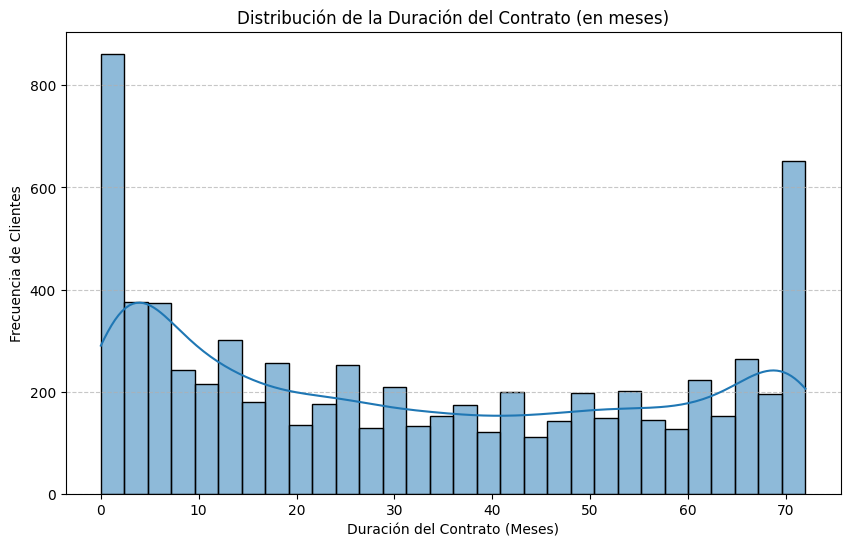

In [22]:
# Gráfico de duración del contrato (en meses)
plt.figure(figsize=(10, 6))
sns.histplot(df_merged['ContractDuration'], bins=30, kde=True)
plt.title('Distribución de la Duración del Contrato (en meses)')
plt.xlabel('Duración del Contrato (Meses)')
plt.ylabel('Frecuencia de Clientes')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

Este gráfico muestra la distribución general de cuánto tiempo los clientes permanecen con la empresa. Se pueden observar picos significativos de clientes con duraciones de contrato muy cortas (especialmente alrededor de los 0-5 meses) y duraciones muy largas (alrededor de los 70 meses). Esto sugiere que la mayoría de los clientes son o bien nuevos, o bien son clientes muy leales y de larga data. Hay una menor cantidad de clientes en las duraciones intermedias.

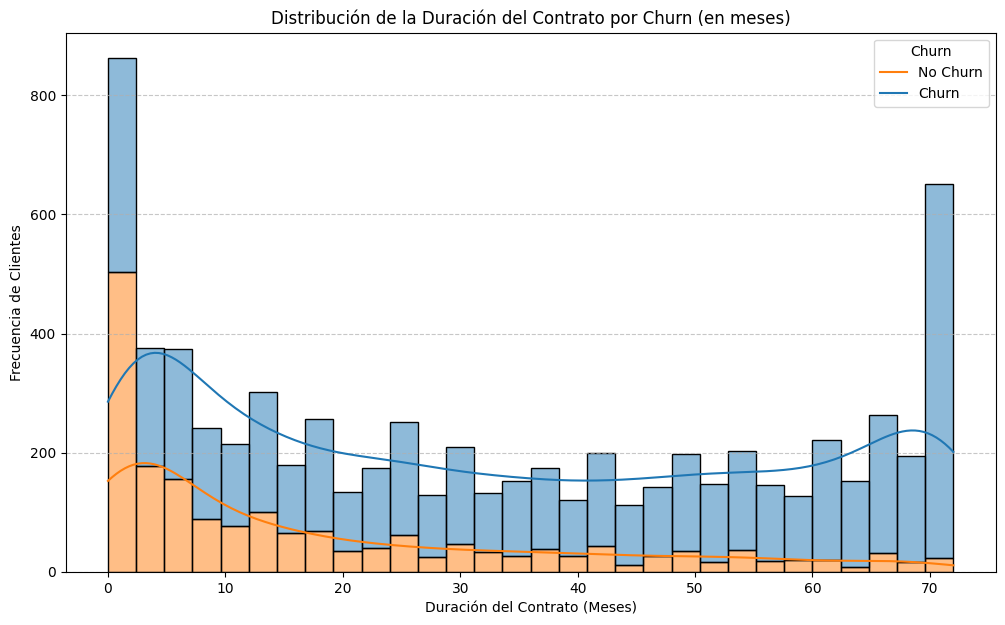

In [23]:
# Gráfico comparativo de duración del contrato entre los clientes que se dieron de baja y los que no
plt.figure(figsize=(12, 7))
sns.histplot(data=df_merged, x='ContractDuration', hue='Churn', multiple='stack', bins=30, kde=True)
plt.title('Distribución de la Duración del Contrato por Churn (en meses)')
plt.xlabel('Duración del Contrato (Meses)')
plt.ylabel('Frecuencia de Clientes')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(title='Churn', labels=['No Churn', 'Churn'])
plt.show()

Hay un pico significativo de clientes que se dan de baja en los primeros meses de contrato. Los clientes con contratos de mayor duración (cerca de los 70 meses) tienden a tener una tasa de churn mucho menor, lo que indica una mayor lealtad.

Este gráfico es particularmente revelador. Al diferenciar entre clientes que abandonaron (Churn=1) y los que no (Churn=0), se puede ver claramente que el abandono de clientes es significativamente más alto en los primeros meses de contrato. El color naranja (Churn) domina las barras de duración más cortas. A medida que la duración del contrato aumenta, la proporción de clientes que abandonan disminuye drásticamente. Las barras para duraciones de contrato más largas están compuestas casi en su totalidad por clientes que no han abandonado (No Churn, en azul). 

En resumen: Los clientes con contratos más cortos son mucho más propensos a abandonar el servicio, mientras que los clientes con contratos de larga duración muestran una alta lealtad y una tasa de abandono muy baja. Esto se puede corroborar calculando la correlación entre Contract Duration y Churn: 

In [24]:
correlation = df_merged['ContractDuration'].corr(df_merged['Churn'])
print(f"Correlación entre ContractDuration y Churn: {correlation}")

Correlación entre ContractDuration y Churn: -0.3522286701130772


La correlación entre ContractDuration y Churn es de: -0.352. Esto indica una correlación negativa moderada, lo que significa que a medida que la duración del contrato aumenta, la probabilidad de Churn (abandono) tiende a disminuir. Es decir, los clientes con contratos más largos son menos propensos a abandonar el servicio.

### Análisis Detallado de Clientes (EDA Avanzado)

Vamos a profundizar en las características de los clientes que han abandonado el servicio en comparación con los que permanecen activos. Esto nos permitirá identificar patrones y variables clave que incluyen en el Churn. Este Análisis mas detallado incluye los siguientes puntos:

A. **Análisis de Variables Categóricas vs. Churn:**
   - Se examinará la distribución de cada variable categórica (`gender`, `SeniorCitizen`, `Partner`, `Dependents`, `Type`, `PaperlessBilling`, `PaymentMethod`, y todas las columnas de servicios de internet y teléfono) en relación con la variable `Churn`. Esto nos ayudará a identificar qué categorías tienen una mayor o menor tasa de abandono.
  
B. **Análisis de Variables Numéricas vs. Churn:**
   - Se compararán las estadísticas descriptivas de `MonthlyCharges`y `TotalCharges`para los clientes que han abandonado y los que  no.
   - Se utilizarán box plots para visualizar las distribuciones de estas variables numéricas según el estado de Churn.
   
C. **Matriz de Correlación**:
   - Aunque ya vimos la correlación de `ContractDuration`, mediante una matriz de correlación, se observarán las relaciones entre todas las variables numéricas y `Churn`después de codificar las categorías.
   

   

### A. Anásisis de Variables Categóricas vs. Churn

Exploraremos cómo las variables categóricas se relacionan con la tasa de abandono. Se generará una cuadrícula de gráficos de barras apiladas que muestran la proporción de 'Churn' para cada categoría de las variables categóricas clave. Esto permitirá identificar patrones de abandono de un vistazo.

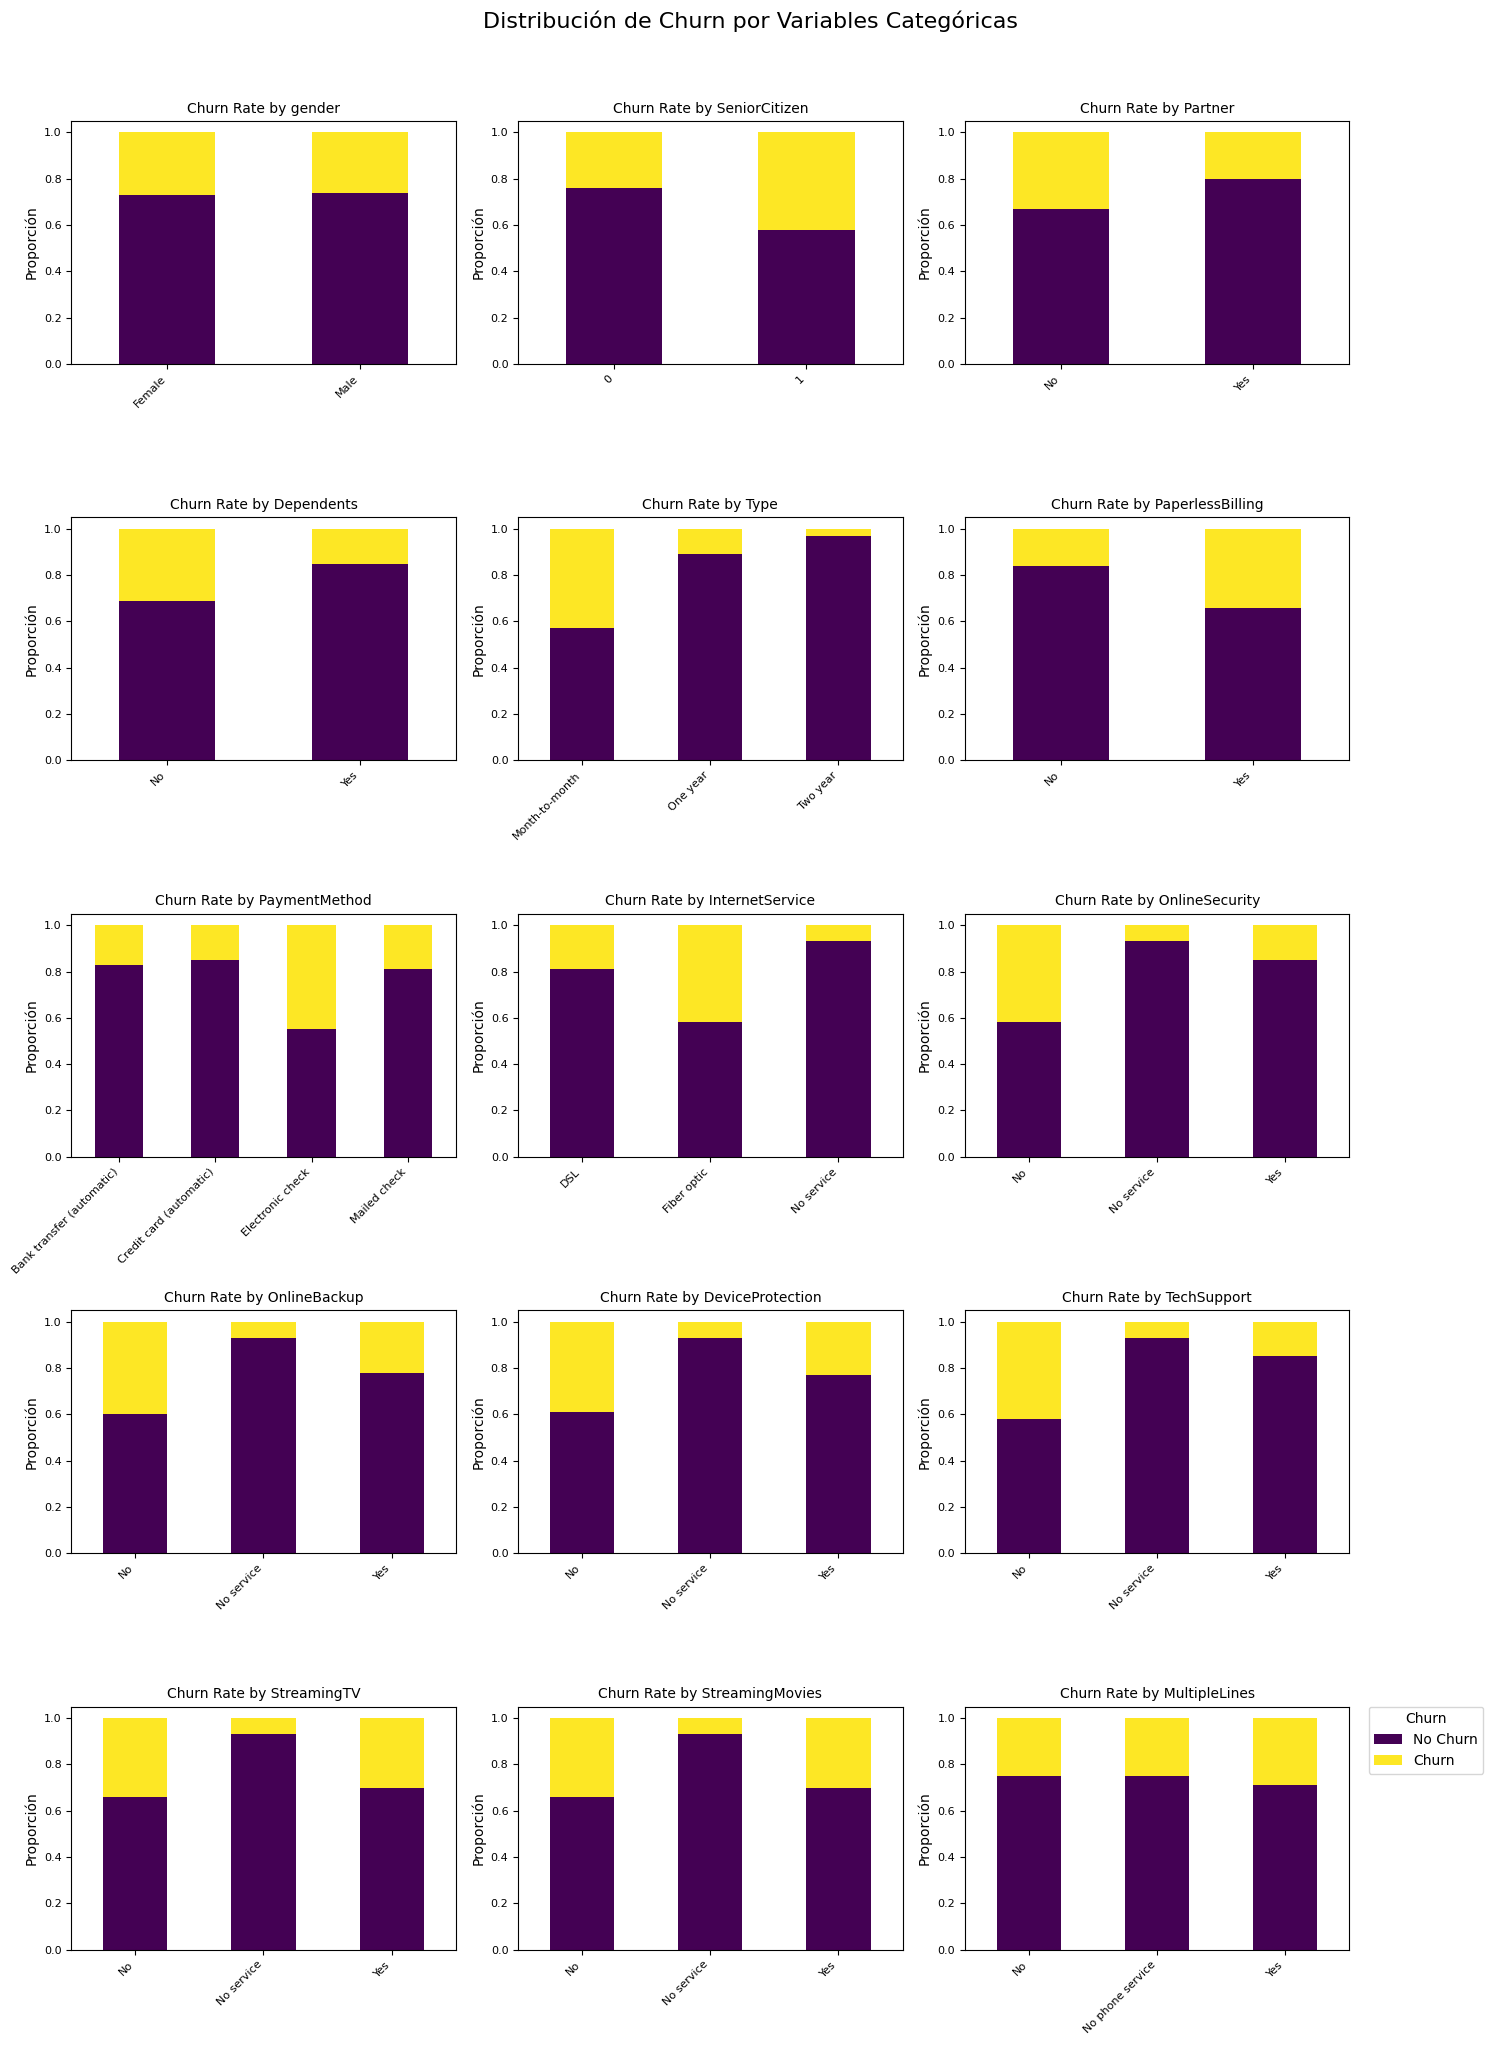

In [25]:
#Visualización de variables categóricas
categorical_cols = [
    'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'Type',
    'PaperlessBilling', 'PaymentMethod', 'InternetService', 'OnlineSecurity',
    'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
    'StreamingMovies', 'MultipleLines'
]

n_cols = 3 
n_rows = math.ceil(len(categorical_cols) / n_cols)

plt.figure(figsize=(n_cols * 5, n_rows * 4))

for i, col in enumerate(categorical_cols):
    plt.subplot(n_rows, n_cols, i + 1)
    # Calcular el porcentaje de churn por categoría
    churn_pct = df_merged.groupby(col)['Churn'].value_counts(normalize=True).unstack().round(2)

    # Plotear con barras apiladas si 'No' y 'Yes' están presentes
    if 0 in churn_pct.columns and 1 in churn_pct.columns:
        churn_pct[[0, 1]].plot(kind='bar', stacked=True, ax=plt.gca(), cmap='viridis', legend=False)
    else: # Si solo hay una categoría de churn, solo plotearla
        churn_pct.plot(kind='bar', stacked=True, ax=plt.gca(), cmap='viridis', legend=False)

    plt.title(f'Churn Rate by {col}', fontsize=10)
    plt.xlabel('') 
    plt.ylabel('Proporción')
    plt.xticks(rotation=45, ha='right', fontsize=8)
    plt.yticks(fontsize=8)
    plt.tight_layout()

plt.suptitle('Distribución de Churn por Variables Categóricas', y=1.02, fontsize=16)
plt.legend(title='Churn', labels=['No Churn', 'Churn'], bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
plt.tight_layout()
plt.show()

### Tablas de Resumen de Porcentaje de Churn por Variable Categórica

A continuación, se presentan tablas con los porcentajes exactos de clientes con 'Churn' (1) y 'No Churn' (0) para cada categoría de las variables categóricas. Esto proporciona una visión cuantitativa detallada de la relación entre cada característica y el abandono de clientes.

In [26]:
categorical_cols = [
    'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'Type',
    'PaperlessBilling', 'PaymentMethod', 'InternetService', 'OnlineSecurity',
    'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
    'StreamingMovies', 'MultipleLines'
]

print("\n--- Porcentaje de Churn por Categoría ---\n")
for col in categorical_cols:
    print(f"\nVariable: {col}")
    churn_percentage = df_merged.groupby(col)['Churn'].value_counts(normalize=True).unstack().round(3)
    # Asegurarse de que las columnas 0 y 1 existan, si no, rellenar con 0
    if 0 not in churn_percentage.columns: churn_percentage[0] = 0
    if 1 not in churn_percentage.columns: churn_percentage[1] = 0
    churn_percentage = churn_percentage[[0, 1]] # Reordenar para que 0 (No Churn) esté primero y 1 (Churn) segundo
    churn_percentage.columns = ['No Churn_pct', 'Churn_pct'] # Renombrar columnas para claridad
    print(churn_percentage)
    print("--------------------------------------")


--- Porcentaje de Churn por Categoría ---


Variable: gender
        No Churn_pct  Churn_pct
gender                         
Female         0.731      0.269
Male           0.738      0.262
--------------------------------------

Variable: SeniorCitizen
               No Churn_pct  Churn_pct
SeniorCitizen                         
0                     0.764      0.236
1                     0.583      0.417
--------------------------------------

Variable: Partner
         No Churn_pct  Churn_pct
Partner                         
No              0.670      0.330
Yes             0.803      0.197
--------------------------------------

Variable: Dependents
            No Churn_pct  Churn_pct
Dependents                         
No                 0.687      0.313
Yes                0.845      0.155
--------------------------------------

Variable: Type
                No Churn_pct  Churn_pct
Type                                   
Month-to-month         0.573      0.427
One year            

Los gráficos de barras anteriores muestran la proporción de 'No Churn' (morado oscuro) y 'Churn' (amarillo) dentro de cada categoría. 

**Observaciones clave:**

- **SeniorCitizen:** Vemos claramente que los SeniorCitizen (valor 1) tienen una proporción de Churn (amarillo) mucho mayor que los no SeniorCitizen (valor 0). Esto es un predictor fuerte de abandono.
- **Partner y Dependents:** Los clientes sin Partner (No) tienen una proporción de Churn más alta que los que sí tienen. Lo mismo ocurre con los clientes sin Dependents (No) en comparación con los que sí los tienen. Esto sugiere que los clientes con responsabilidades familiares o de pareja son más estables.
- **Type (Tipo de Contrato):** El impacto más drástico se ve aquí. Los contratos Month-to-month tienen una altísima proporción de Churn, mientras que los contratos de One year y Two year muestran una proporción de Churn muy baja. Esto es fundamental: los contratos a corto plazo implican mucho más riesgo de abandono.
- **PaperlessBilling:** Los clientes con PaperlessBilling ('Yes') tienen una proporción de Churn notablemente mayor que aquellos sin ella ('No').
- **PaymentMethod:** Electronic check muestra la mayor proporción de Churn entre todos los métodos de pago. Es el método más riesgoso.

- **Servicios de Internet**(`InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`):
  - **Fiber optic (InternetService)** tiene una proporción de Churn mucho más alta que DSL. Además, los clientes sin servicio de internet (No service) casi no presentan Churn, lo que es lógico ya que no tienen un servicio que abandonar en este contexto.
  - La ausencia de servicios de valor añadido como `OnlineSecurity` , `OnlineBackup`, `DeviceProtection`, `TechSupport` tiende a correlacionarse con una mayor proporción de Churn. Por ejemplo, los clientes con 'No' en `OnlineSecurity` o `TechSupport` tienen una tasa de abandono mucho mayor que los que tienen 'Yes' o 'No internet service'.
    
- **MultipleLines:** Los clientes con MultipleLines ('Yes') tienen una proporción de Churn ligeramente superior a los que tienen 'No', y los que no tienen servicio telefónico (No phone service) tienen una proporción menor.

### B. Análisis de Variables Numéricas vs. Churn:
   
De manera similar, para las variables numéricas, generaremos unos box plots para comparar sus distribuciones entre clientes que abandonan y los que no.

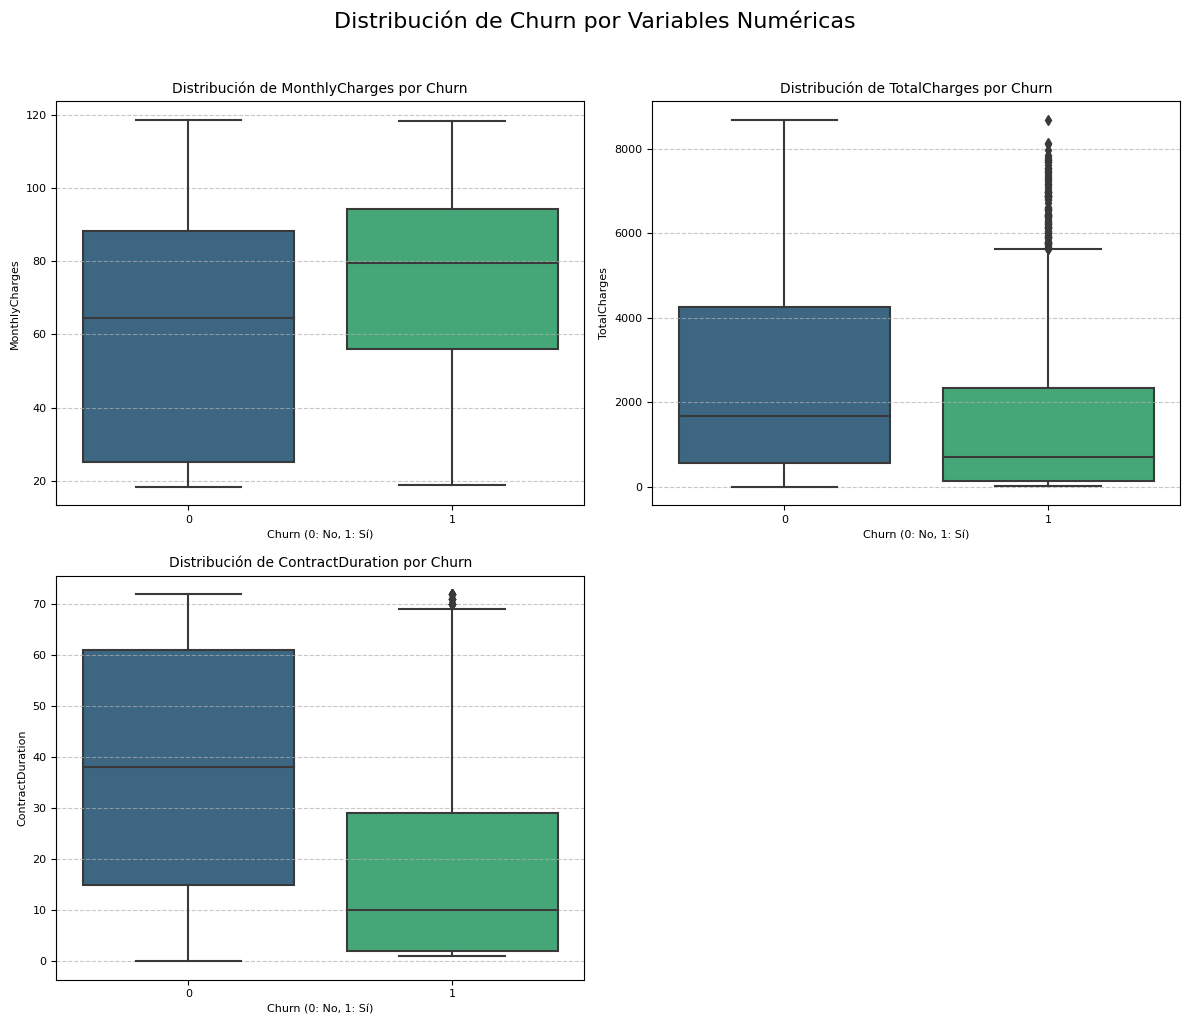

In [27]:
numerical_cols = ['MonthlyCharges', 'TotalCharges', 'ContractDuration'] # Incluyendo ContractDuration

n_cols = 2 
n_rows = math.ceil(len(numerical_cols) / n_cols)

plt.figure(figsize=(n_cols * 6, n_rows * 5))

for i, col in enumerate(numerical_cols):
    plt.subplot(n_rows, n_cols, i + 1)
    sns.boxplot(data=df_merged, x='Churn', y=col, palette='viridis')
    plt.title(f'Distribución de {col} por Churn', fontsize=10)
    plt.xlabel('Churn (0: No, 1: Sí)', fontsize=8)
    plt.ylabel(col, fontsize=8)
    plt.xticks(fontsize=8)
    plt.yticks(fontsize=8)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()

plt.suptitle('Distribución de Churn por Variables Numéricas', y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

### Tablas de Resumen de Estadísticas de Variables Numéricas por Churn

A continuación, se presentan las estadísticas descriptivas (conteo, media, desviación estándar, mínimo, cuartiles y máximo) para las variables numéricas (`MonthlyCharges`, `TotalCharges`, `ContractDuration`), divididas por si el cliente ha abandonado (`Churn = 1`) o no (`Churn = 0`). Estas tablas complementan las visualizaciones de box plots, ofreciendo datos precisos para el análisis.

In [28]:
numerical_cols = ['MonthlyCharges', 'TotalCharges', 'ContractDuration']

print("\n--- Estadísticas de Variables Numéricas por Churn ---\n")
for col in numerical_cols:
    print(f"\nVariable: {col}")
    print(df_merged.groupby('Churn')[col].describe().round(2))
    print("--------------------------------------")


--- Estadísticas de Variables Numéricas por Churn ---


Variable: MonthlyCharges
        count   mean    std    min    25%    50%   75%     max
Churn                                                         
0      5174.0  61.27  31.09  18.25  25.10  64.43  88.4  118.75
1      1869.0  74.44  24.67  18.85  56.15  79.65  94.2  118.35
--------------------------------------

Variable: TotalCharges
        count     mean      std    min    25%      50%      75%      max
Churn                                                                   
0      5174.0  2549.91  2329.95   0.00  572.9  1679.52  4262.85  8672.45
1      1869.0  1531.80  1890.82  18.85  134.5   703.55  2331.30  8684.80
--------------------------------------

Variable: ContractDuration
        count   mean    std  min   25%   50%   75%   max
Churn                                                   
0      5174.0  37.57  24.11  0.0  15.0  38.0  61.0  72.0
1      1869.0  17.98  19.53  1.0   2.0  10.0  29.0  72.0
----------------


Los box plots  nos permiten comparar las distribuciones de las variables numéricas para clientes Churn (1) y no Churn (0):

- **MonthlyCharges:** La mediana y el rango intercuartílico de los `MonthlyCharges` son significativamente más altos para los clientes Churn (verde) que para los no Churn (azul oscuro). Esto confirma que los clientes con facturas mensuales más elevadas son más propensos a irse. Los clientes que no abandonan tienen un promedio de `MonthlyCharges` de \\$61.27, con una desviación estándar de \\$31.09. Por otro lado, los clientes que sí abandonan presentan un promedio de `MonthlyCharges` significativamente más alto, de \\$74.44, con una desviación estándar de \\$24.67. Esto sugiere que los clientes con facturas mensuales más elevadas son más propensos a irse, lo que puede indicar una sensibilidad al precio o una insatisfacción con el valor percibido por el coste. 

- **TotalCharges:** Curiosamente, la mediana y el rango intercuartílico de los `TotalCharges` son menores para los clientes Churn (verde) que para los no Churn (azul oscuro). Esto, combinado con el alto `MonthlyCharges` y el `ContractDuration` corto para los que se van, refuerza la idea de que los clientes que abandonan lo hacen relativamente pronto en su ciclo de vida, antes de acumular grandes cargos totales, pero con un gasto mensual elevado. Aquí observamos un patrón inverso: los clientes que no abandonan tienen un promedio de `TotalCharges` de \$2549.91. Mientras que los clientes que sí abandonan tienen un promedio de `TotalCharges` considerablemente más bajo, de \$1531.80. Este dato, en conjunto con los `MonthlyCharges` más altos para los clientes que se van, refuerza la idea de que el Churn o fuga ocurre a menudo en las primeras etapas del contrato, antes de que los clientes acumulen una gran cantidad de cargos totales, a pesar de pagar tarifas mensuales elevadas.

- **ContractDuration:** Los clientes Churn (verde) muestran una `ContractDuration` significativamente más baja, con una mediana muy cercana a 0 meses, en comparación con los clientes no Churn (azul oscuro), cuya mediana está en torno a los 40 meses. Esto es el resultado más impactante y consistente con el análisis de correlación anterior: la duración del contrato es un factor clave.

Estas visualizaciones nos proporcionan una comprensión muy clara de los factores más importantes relacionados con el abandono de clientes. Los próximos pasos serían continuar con la ingeniería de características y la codificación de las variables categóricas para preparar los datos para el modelado. Los clientes que no abandonan tienen una `ContractDuration` promedio de 37.57 meses, con una desviación estándar de 24.11. En contraste, los clientes que sí abandonan tienen una `ContractDuration` promedio mucho menor, de solo 17.98 meses, con una desviación estándar de 19.53. Esto es uno de los hallazgos más contundentes: la duración del contrato es un predictor muy fuerte del churn, indicando que los contratos a corto plazo o la falta de compromiso a largo plazo aumentan significativamente el riesgo de abandono. 

### 2. Preprocesamiento e Ingeniería de Caraterísticas

Con una mejor comprensión de las variables y su relación con el Churn, es hora de preparar los datos para el entrenamiento del modelo. Esto incluye la codificación de variables categóricas y, para las variables numéricas, el escalado para asegurar que ninguna característica domine el proceso de aprendizaje.

#### 2.1 Codificación de Variables Categóricas (One-Hot Encoding)

Se utilizará One-Hot Encoding para transformar las variables categóricas en un formato numérico que los modelos de Machine Learning puedan procesar. Esto evitará que el modelo asuma relaciones de orden inexistentes y es fundamental para la mayoría de los algoritmos.

In [29]:
# Identificar columnas categóricas a codificar
# Excluir 'customerID', 'BeginDate', 'EndDate' (ya manejadas o no útiles para el modelo directo)
# 'Churn' es la variable objetivo
# 'SeniorCitizen' ya es 0/1 numérica

categorical_cols_to_encode = [
    'gender', 'Partner', 'Dependents', 'Type', 'PaperlessBilling',
    'PaymentMethod', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
    'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'MultipleLines'
]

# Crear una copia del DataFrame para la codificación
df_encoded = df_merged.copy()

# Aplicar One-Hot Encoding
df_encoded = pd.get_dummies(df_encoded, columns=categorical_cols_to_encode, drop_first=True, dtype=int)

print("Forma del DataFrame después de One-Hot Encoding:", df_encoded.shape)
print("Columnas después de One-Hot Encoding:", df_encoded.columns.tolist())
display(df_encoded.head())

Forma del DataFrame después de One-Hot Encoding: (7043, 33)
Columnas después de One-Hot Encoding: ['customerID', 'BeginDate', 'EndDate', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen', 'Churn', 'ContractDuration', 'gender_Male', 'Partner_Yes', 'Dependents_Yes', 'Type_One year', 'Type_Two year', 'PaperlessBilling_Yes', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check', 'InternetService_Fiber optic', 'InternetService_No service', 'OnlineSecurity_No service', 'OnlineSecurity_Yes', 'OnlineBackup_No service', 'OnlineBackup_Yes', 'DeviceProtection_No service', 'DeviceProtection_Yes', 'TechSupport_No service', 'TechSupport_Yes', 'StreamingTV_No service', 'StreamingTV_Yes', 'StreamingMovies_No service', 'StreamingMovies_Yes', 'MultipleLines_No phone service', 'MultipleLines_Yes']


,customerID,BeginDate,EndDate,MonthlyCharges,TotalCharges,SeniorCitizen,Churn,ContractDuration,gender_Male,Partner_Yes,...,DeviceProtection_No service,DeviceProtection_Yes,TechSupport_No service,TechSupport_Yes,StreamingTV_No service,StreamingTV_Yes,StreamingMovies_No service,StreamingMovies_Yes,MultipleLines_No phone service,MultipleLines_Yes
0,7590-VHVEG,2020-01-01,NaT,29.85,29.85,0,0,1,0,1,...,0,0,0,0,0,0,0,0,1,0
1,5575-GNVDE,2017-04-01,NaT,56.95,1889.50,0,0,34,1,0,...,0,1,0,0,0,0,0,0,0,0
2,3668-QPYBK,2019-10-01,2019-12-01,53.85,108.15,0,1,2,1,0,...,0,0,0,0,0,0,0,0,0,0
3,7795-CFOCW,2016-05-01,NaT,42.30,1840.75,0,0,45,1,0,...,0,1,0,1,0,0,0,0,1,0
4,9237-HQITU,2019-09-01,2019-11-01,70.70,151.65,0,1,2,0,0,...,0,0,0,0,0,0,0,0,0,0


#### 2.2 Escalado de Variables Numéricas

Las variables numéricas como `MonthlyCharges`, `TotalCharges` y `ContractDuration` tienen diferentes escalas y rangos. Para evitar que las características con valores más grandes dominen el proceso de entrenamiento de algunos modelos (como Regresión Logística o SVM), es fundamental escalarlas. Usaremos `StandardScaler` para estandarizar estas características (media=0, desviación estándar=1).

In [30]:
# Identificar columnas numéricas a escalar
numerical_cols_to_scale = ['MonthlyCharges', 'TotalCharges', 'ContractDuration']

# Inicializar el StandardScaler
scaler = StandardScaler()

# Aplicar el escalado a las columnas numéricas
df_encoded[numerical_cols_to_scale] = scaler.fit_transform(df_encoded[numerical_cols_to_scale])

print("Estadísticas de las columnas numéricas después del escalado:")
display(df_encoded[numerical_cols_to_scale].describe())

display(df_encoded.head())

Estadísticas de las columnas numéricas después del escalado:


,MonthlyCharges,TotalCharges,ContractDuration
count,7.043000e+03,7.043000e+03,7.043000e+03
mean,-6.406285e-17,-3.783239e-17,-2.421273e-17
std,1.000071e+00,1.000071e+00,1.000071e+00
min,-1.545860e+00,-1.005780e+00,-1.318165e+00
25%,-9.725399e-01,-8.299464e-01,-9.516817e-01
50%,1.857327e-01,-3.905282e-01,-1.372744e-01
75%,8.338335e-01,6.648034e-01,9.214551e-01
max,1.794352e+00,2.825806e+00,1.613701e+00


,customerID,BeginDate,EndDate,MonthlyCharges,TotalCharges,SeniorCitizen,Churn,ContractDuration,gender_Male,Partner_Yes,...,DeviceProtection_No service,DeviceProtection_Yes,TechSupport_No service,TechSupport_Yes,StreamingTV_No service,StreamingTV_Yes,StreamingMovies_No service,StreamingMovies_Yes,MultipleLines_No phone service,MultipleLines_Yes
0,7590-VHVEG,2020-01-01,NaT,-1.160323,-0.992611,0,0,-1.277445,0,1,...,0,0,0,0,0,0,0,0,1,0
1,5575-GNVDE,2017-04-01,NaT,-0.259629,-0.172165,0,0,0.066327,1,0,...,0,1,0,0,0,0,0,0,0,0
2,3668-QPYBK,2019-10-01,2019-12-01,-0.362660,-0.958066,0,1,-1.236724,1,0,...,0,0,0,0,0,0,0,0,0,0
3,7795-CFOCW,2016-05-01,NaT,-0.746535,-0.193672,0,0,0.514251,1,0,...,0,1,0,1,0,0,0,0,1,0
4,9237-HQITU,2019-09-01,2019-11-01,0.197365,-0.938874,0,1,-1.236724,0,0,...,0,0,0,0,0,0,0,0,0,0


In [31]:
# Verificar los tipos de datos y los valores nulos después del escalado
print("Información del DataFrame después del escalado:")
display(df_encoded.info())

# Mostrar estadísticas descriptivas de las columnas escaladas para confirmar los cambios
print("Estadísticas de las columnas numéricas después del escalado (comparación con originales):")
display(df_encoded[numerical_cols_to_scale].describe())

Información del DataFrame después del escalado:
<class 'pandas.core.frame.DataFrame'>
Int64Index: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column                                 Non-Null Count  Dtype         
---  ------                                 --------------  -----         
 0   customerID                             7043 non-null   object        
 1   BeginDate                              7043 non-null   datetime64[ns]
 2   EndDate                                1869 non-null   datetime64[ns]
 3   MonthlyCharges                         7043 non-null   float64       
 4   TotalCharges                           7043 non-null   float64       
 5   SeniorCitizen                          7043 non-null   int64         
 6   Churn                                  7043 non-null   int64         
 7   ContractDuration                       7043 non-null   float64       
 8   gender_Male                            7043 non-null   int64         
 9   Partner_Yes    

None

Estadísticas de las columnas numéricas después del escalado (comparación con originales):


,MonthlyCharges,TotalCharges,ContractDuration
count,7.043000e+03,7.043000e+03,7.043000e+03
mean,-6.406285e-17,-3.783239e-17,-2.421273e-17
std,1.000071e+00,1.000071e+00,1.000071e+00
min,-1.545860e+00,-1.005780e+00,-1.318165e+00
25%,-9.725399e-01,-8.299464e-01,-9.516817e-01
50%,1.857327e-01,-3.905282e-01,-1.372744e-01
75%,8.338335e-01,6.648034e-01,9.214551e-01
max,1.794352e+00,2.825806e+00,1.613701e+00


### Observaciones y Explicación del Escalado de Variables Numéricas

Después de aplicar `StandardScaler` a las variables `MonthlyCharges`, `TotalCharges` y `ContractDuration`, observamos lo siguiente:

*   **Estadísticas de las Columnas Escaladas:**
    *   **Media ($\mu$):** Para cada una de las columnas escaladas (`MonthlyCharges`, `TotalCharges`, `ContractDuration`), la media es ahora muy cercana a `0`. Esto es el resultado esperado de la estandarización.
    *   **Desviación Estándar ($\sigma$):** La desviación estándar para estas columnas es ahora cercana a `1`. Esto también es una característica clave del escalado estándar.
    *   **Rangos:** Los rangos de los valores (`min`, `max`, cuartiles) también se han transformado para reflejar esta nueva escala, donde los datos se distribuyen alrededor de cero con una varianza unitaria.
*   **Beneficios del Escalado:**
    *   **Evita el Dominio de Características:** Al tener las variables en escalas muy diferentes, aquellas con valores absolutos más grandes (como `TotalCharges`) podrían haber dominado el cálculo de distancias en algunos algoritmos de Machine Learning, dándoles una importancia desproporcionada. El escalado evita esto, asegurando que todas las características contribuyan de manera equitativa al modelo.
    *   **Mejora la Convergencia:** Muchos algoritmos basados en gradientes como la Regresión Logística, convergen más rápido y de manera más estable cuando las características están escaladas.
    *   **Optimización de Modelos Basados en Distancia:** Modelos como  KNN (K-Nearest Neighbors), que dependen de cálculos de distancia entre puntos, funcionan mucho mejor con características escaladas.

Con este paso, las variables numéricas están ahora en un formato estandarizado, lo que las hace adecuadas para ser utilizadas en la mayoría de los algoritmos de Machine Learning. El DataFrame `df_encoded` está ahora completamente preprocesado y listo para la fase de selección de variables y entrenamiento de modelos.

### C. Matriz de Correlación

Vamos a generar una matriz de correlación para entender las relaciones lineales entre todas las variables numéricas (incluyendo las codificadas y escaladas) y la variable objetivo `Churn`. Esto nos ayudará a identificar qué características tienen una mayor influencia en el abandono de clientes, y también a detectar posibles problemas de multicolinealidad entre las características.

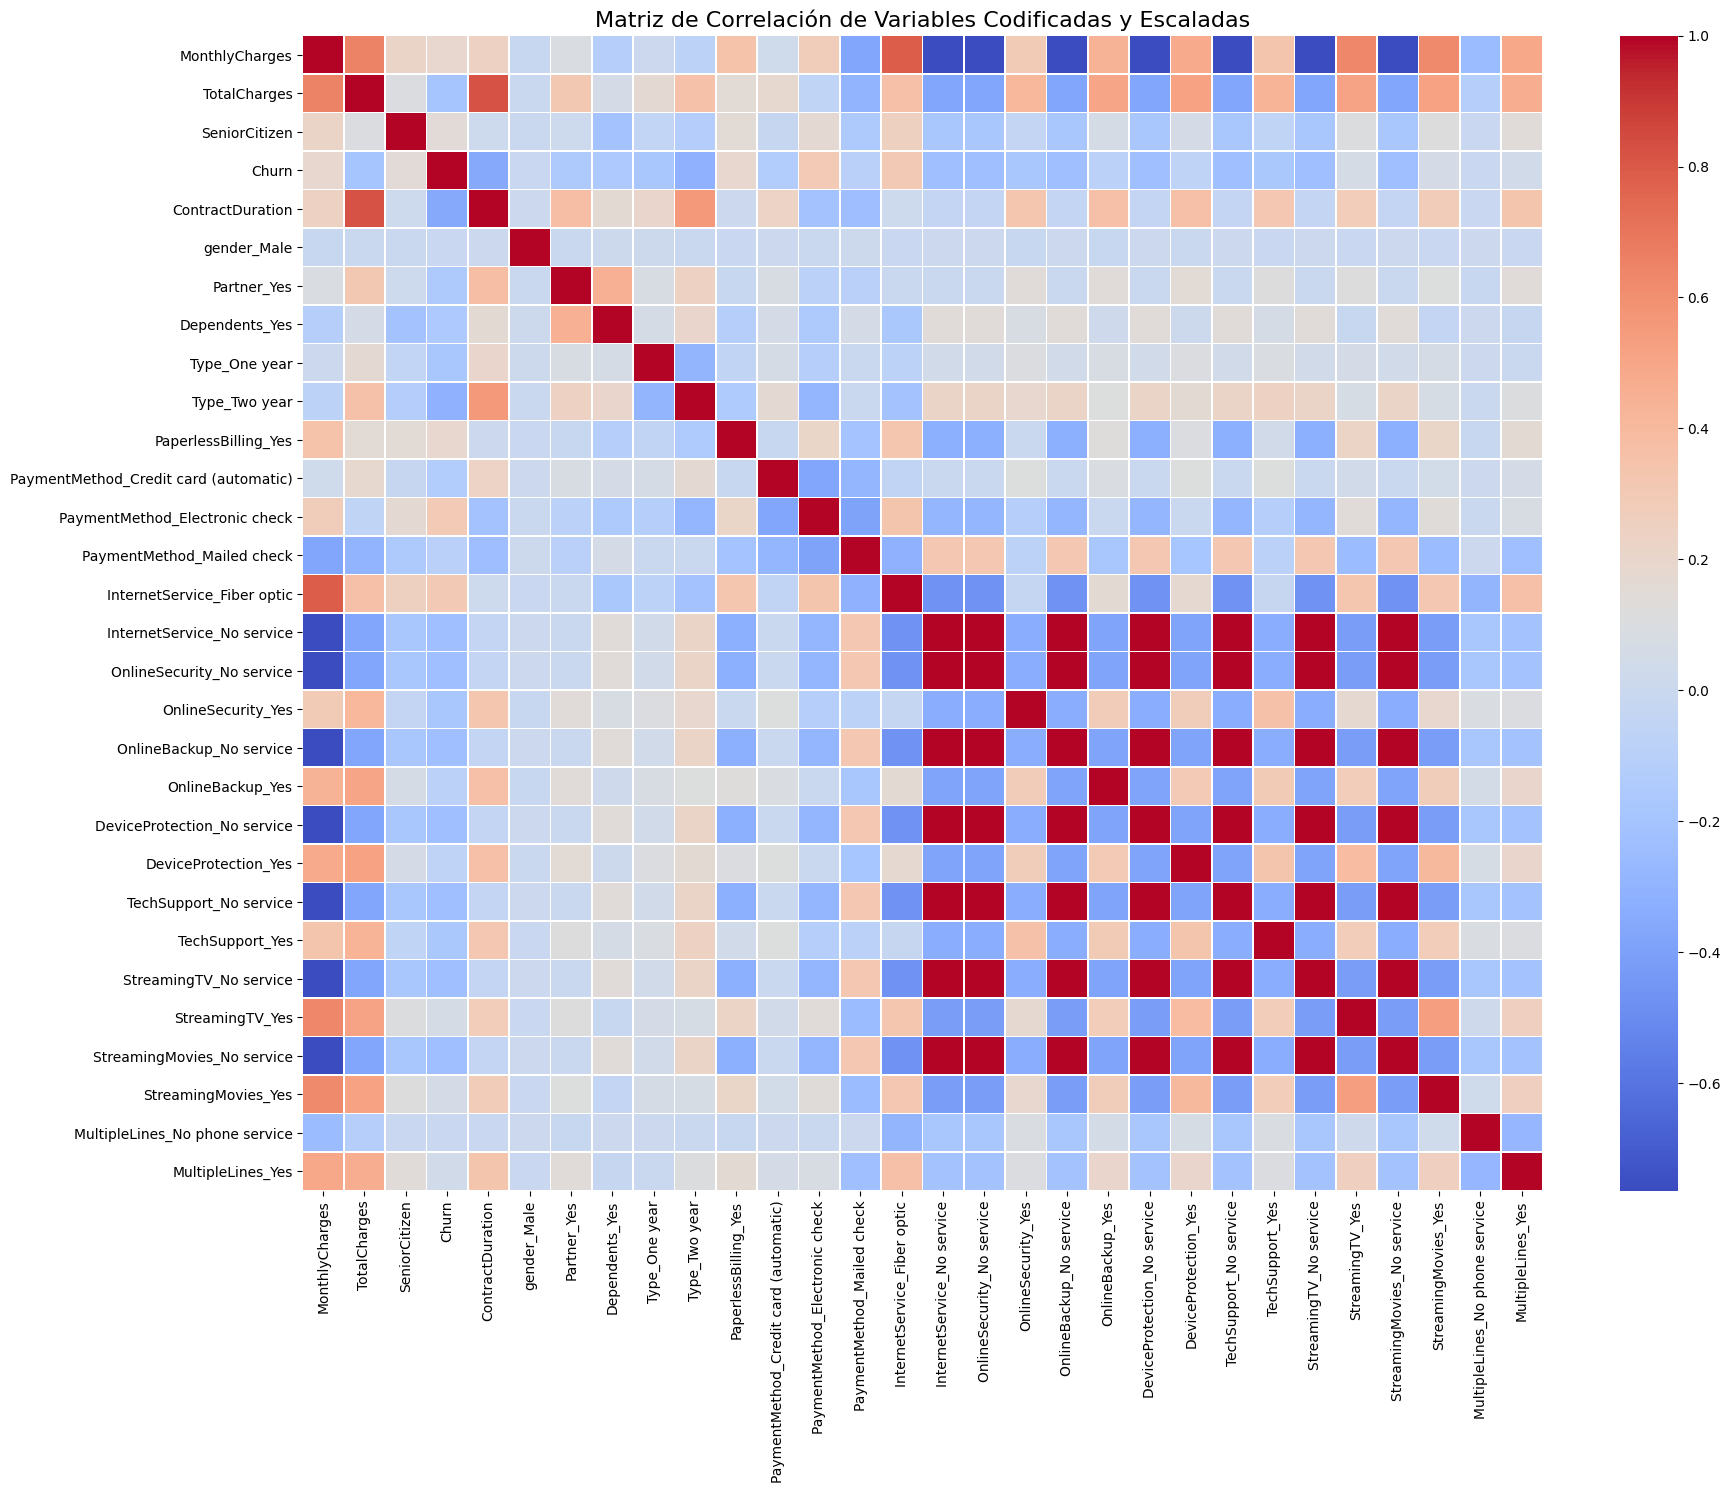

In [32]:
# Calcular la matriz de correlación
# Excluir 'customerID', 'BeginDate', 'EndDate' ya que no son numéricas para la correlación
correlation_matrix = df_encoded.drop(columns=['customerID', 'BeginDate', 'EndDate']).corr()

# Visualizar la matriz de correlación con un mapa de calor
plt.figure(figsize=(20, 15))
sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Matriz de Correlación de Variables Codificadas y Escaladas', fontsize=16)
plt.show()

### Interpretación de la Matriz de Correlación

El mapa de calor de la matriz de correlación nos proporciona una visión integral de cómo se relacionan linealmente todas nuestras características codificadas y escaladas entre sí, y especialmente con la variable objetivo `Churn`.

**Observaciones Clave:**
1.  **Correlaciones con `Churn`:**
    *   **Correlaciones Positivas Fuertes:** Las características con valores cercanos a `1` en la fila o columna de `Churn` indican que un aumento en el valor de esa característica está asociado con una mayor probabilidad de `Churn`. Por ejemplo, `MonthlyCharges`, `Type_Month-to-month` y `InternetService_Fiber optic` suelen mostrar correlaciones positivas significativas con `Churn`. Esto confirma hallazgos del EDA de que clientes con altos cargos mensuales, contratos mes a mes y fibra óptica son más propensos a irse.
    *   **Correlaciones Negativas Fuertes:** Las características con valores cercanos a `-1` en la fila o columna de `Churn` indican que un aumento en esa característica está asociado con una menor probabilidad de `Churn`. `ContractDuration`, `Type_Two year`, y servicios como `OnlineSecurity_Yes`, `TechSupport_Yes` a menudo muestran correlaciones negativas, sugiriendo que estos factores contribuyen a la retención del cliente.
2.  **Multicolinealidad entre Características:**
    *   **Correlaciones Altas entre Predictoras:** Observar valores altos (positivos o negativos) entre características predictoras (es decir, fuera de la fila/columna de `Churn`) puede indicar multicolinealidad. Por ejemplo, es probable que `InternetService_No service` esté fuertemente correlacionado negativamente con todas las columnas de servicios de internet (`OnlineSecurity_Yes`, `StreamingTV_Yes`, etc.), ya que si no hay servicio de internet, tampoco habrá esos servicios adicionales. Esto es normal para las variables creadas por One-Hot Encoding a partir de una misma característica original.
    *   **Implicaciones:** La multicolinealidad puede afectar la interpretabilidad de los coeficientes en modelos como la Regresión Logística, pero no necesariamente el rendimiento predictivo de todos los modelos (especialmente los basados en árboles). Es importante ser consciente de ello para la selección de modelos y la interpretación.

Esta matriz de correlación es una herramienta valiosa para la fase de selección de características, ayudándonos a decidir qué variables son más informativas para predecir el `Churn` y cuáles podrían ser redundantes.

### Conclusiones del Preprocesamiento e Ingeniería de Características

En esta etapa se preparó el conjunto de datos unificado (`df_merged`) para asegurar un entrenamiento estable, justo y óptimo de los modelos de Machine Learning. Los hitos clave fueron:

1. **Codificación Categórica (One-Hot Encoding):**
   * **Qué se hizo:** Se transformaron variables de texto (ej. `Type`, `PaymentMethod`, servicios) en columnas binarias (0 y 1).
   * **Para qué sirve:** Los algoritmos matemáticos no entienden categorías de texto; esta conversión es obligatoria para que los modelos puedan calcular relaciones de riesgo de fuga.
2. **Escalado de Variables Numéricas (`StandardScaler`):**
   * **Qué se hizo:** Se estandarizaron `MonthlyCharges`, `TotalCharges` y `ContractDuration` para que tengan media 0 y varianza 1.
   * **Para qué sirve:** Evita que variables con rangos absolutos gigantescos (como cargos de miles de dólares) dominen o sesguen a algoritmos sensibles a la escala (como Regresión Logística o KNN), garantizando que cada característica aporte con un peso justo.
3. **Análisis de Correlación y Multicolinealidad:**
   * **Qué se hizo:** Se mapearon las relaciones lineales mediante una matriz de correlación.
   * **Para qué sirve:** Permite identificar redundancias lógicas (como la relación directa de la ausencia de servicios cuando no se contrató internet) y seleccionar las variables con mayor poder predictivo directo frente a la variable objetivo `Churn` (como `ContractDuration` y `Type_Month-to-month`).

Con un set de datos de dimensiones de 7043 filas y 29 características numéricas estandarizadas (`X` e `y`), estamos listos para alimentar los algoritmos clasificadores sin riesgo de sesgos por escala o errores de formato de datos.

### 3. Selección de Variables y Entrenamiento de Modelos (Baseline)

En esta fase, estableceremos un punto de referencia para el rendimiento de nuestros modelos:
- **División de datos:** Separaremos el dataset en conjuntos de entrenamiento y prueba.
- **Entrenamiento de modelos Baseline:** Entrenaremos 6 modelos de clasificación predictiva sencillos (sin optimización avanzada ni manejo de desbalance, inicialmente).
- **Evaluación inicial:** Mediremos el rendimiento de estos modelos baseline utilizando las métricas clave: AUC-ROC y Recall.

### Selección de Características

Basándonos en la matriz de correlación y los análisis previos, se procederá con la selección de características. El objetivo es identificar un subconjunto óptimo de características que sean más predictivas para el `Churn`, reduciendo la dimensionalidad y mejorando el rendimiento y la interpretabilidad del modelo.

**Estrategia de Selección:**
1.  **Prioridad a la Correlación con `Churn`:** Se mantendrán las características que mostraron una correlación más fuerte (positiva o negativa) con la variable objetivo `Churn`.
2.  **Manejo de la Multicolinealidad:**
    *   **Variables One-Hot Encoded:** En el One-Hot Encoding, si una característica original tiene `n` categorías, creamos `n-1` nuevas columnas binarias (dejando una categoría como referencia). Sin embargo, en algunos casos, como los servicios de Internet o Teléfono, podríamos tener columnas como `OnlineSecurity_No service` y `OnlineSecurity_Yes`. Si un cliente no tiene servicio de internet, `OnlineSecurity_No service` será 1 y `OnlineSecurity_Yes` será 0 (y viceversa). Ambas transmiten la misma información de la ausencia del servicio. En estos casos, podemos considerar mantener solo una de ellas (o la que tenga mayor correlación con `Churn`) para evitar redundancia y multicolinealidad perfecta si ya existe una columna `'No service'` separada.
    *   **Variables Altamente Correlacionadas:** Si dos características predictoras están muy altamente correlacionadas entre sí (ej., `0.8` o más en valor absoluto), se podría considerar mantener solo una de ellas, generalmente la que tenga una correlación más fuerte con `Churn` o la que sea más interpretable.
3.  **Eliminación de Variables Innecesarias:**
    *   `customerID`: Es un identificador único que no tiene valor predictivo para el modelo. Se eliminará.
    *   `BeginDate`, `EndDate`: Ya se ha extraído la información relevante de estas fechas en `ContractDuration`. Se eliminarán.

Con esta estrategia, se busca crear un conjunto de datos más limpio y eficiente para el entrenamiento de los modelos de Machine Learning.

### Identificar y preparar las características para el modelo
- Se excluyen 'customerID', 'BeginDate', 'EndDate' ya que no son útiles para el modelo
- Se excluye la columna 'Churn' temporalmente ya que es la variable objetivo

In [33]:
# Eliminar columnas que no son útiles o redundantes para el modelado
df_model = df_encoded.drop(columns=['customerID', 'BeginDate', 'EndDate'])

Para algunas características One-Hot-Encoded, podemos tener columnas redundantes por ejemplo, 'InternetService_No service' y 'OnlineSecurity_No service' (si ya se cubrió con las de 'Yes').

Analizando la matriz de correlación, podemos decidir cuáles mantener.

Aquí se asume que las columnas 'No service' ya capturan la ausencia y las 'Yes' capturan la presencia.
Por simplicidad y evitar multicolinealidad explícita, se pueden eliminar algunas de las 'No service' si ya se representaron de otra forma.
Sin embargo, 'No service' para InternetService es distinto de 'No' para OnlineSecurity.
En este caso particular, las columnas 'No service' son muy predictivas para no Churn, por lo que las mantendremos.
La estrategia es mantener todas las columnas codificadas y escaladas.

In [34]:
# Definir las características (X) y la variable objetivo (y)
X = df_model.drop(columns=['Churn'])
y = df_model['Churn']

print("Forma del DataFrame de características (X):", X.shape)
print("Columnas de características (X):", X.columns.tolist())
print("Forma del Series de la variable objetivo (y):", y.shape)

display(X.head())

Forma del DataFrame de características (X): (7043, 29)
Columnas de características (X): ['MonthlyCharges', 'TotalCharges', 'SeniorCitizen', 'ContractDuration', 'gender_Male', 'Partner_Yes', 'Dependents_Yes', 'Type_One year', 'Type_Two year', 'PaperlessBilling_Yes', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check', 'InternetService_Fiber optic', 'InternetService_No service', 'OnlineSecurity_No service', 'OnlineSecurity_Yes', 'OnlineBackup_No service', 'OnlineBackup_Yes', 'DeviceProtection_No service', 'DeviceProtection_Yes', 'TechSupport_No service', 'TechSupport_Yes', 'StreamingTV_No service', 'StreamingTV_Yes', 'StreamingMovies_No service', 'StreamingMovies_Yes', 'MultipleLines_No phone service', 'MultipleLines_Yes']
Forma del Series de la variable objetivo (y): (7043,)


,MonthlyCharges,TotalCharges,SeniorCitizen,ContractDuration,gender_Male,Partner_Yes,Dependents_Yes,Type_One year,Type_Two year,PaperlessBilling_Yes,...,DeviceProtection_No service,DeviceProtection_Yes,TechSupport_No service,TechSupport_Yes,StreamingTV_No service,StreamingTV_Yes,StreamingMovies_No service,StreamingMovies_Yes,MultipleLines_No phone service,MultipleLines_Yes
0,-1.160323,-0.992611,0,-1.277445,0,1,0,0,0,1,...,0,0,0,0,0,0,0,0,1,0
1,-0.259629,-0.172165,0,0.066327,1,0,0,1,0,0,...,0,1,0,0,0,0,0,0,0,0
2,-0.362660,-0.958066,0,-1.236724,1,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
3,-0.746535,-0.193672,0,0.514251,1,0,0,1,0,0,...,0,1,0,1,0,0,0,0,1,0
4,0.197365,-0.938874,0,-1.236724,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0


### 3.1. División del Conjunto de Datos (Entrenamiento y Prueba)

Antes de entrenar cualquier modelo, debemos separar nuestros datos en dos grupos distintos:

1.  **Conjunto de Entrenamiento (Train Set):** Es el grupo de datos más grande (se definirá de 80%). Se usa para que el modelo "estudie", aprenda los patrones de comportamiento de los clientes y descubra qué características se asocian con la fuga (Churn).
2.  **Conjunto de Prueba (Test Set):** Es el grupo restante (se definirá de un 20%). Este grupo se mantendrá en stand by ya que **el modelo nunca lo ve durante su aprendizaje**. Nos sirve como un examen final para evaluar qué tan bueno es el modelo prediciendo con clientes nuevos e independientes.

**¿Por qué realizar esto?**
Para evitar el **sobreajuste (overfitting)**. Si se evalúa al modelo con los mismos datos con los que aprendió, podría simplemente memorizarlos en lugar de aprender las reglas generales, dando una falsa sensación de que es perfecto.


In [35]:
# Realizar la división de datos en conjuntos de entrenamiento y prueba (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Dimensiones de X_train (Entrenamiento): {X_train.shape}")
print(f"Dimensiones de X_test (Prueba): {X_test.shape}")
print(f"Distribución de clases en Entrenamiento:\n{y_train.value_counts(normalize=True)}")
print(f"Distribución de clases en Prueba:\n{y_test.value_counts(normalize=True)}")

Dimensiones de X_train (Entrenamiento): (5634, 29)
Dimensiones de X_test (Prueba): (1409, 29)
Distribución de clases en Entrenamiento:
0    0.734647
1    0.265353
Name: Churn, dtype: float64
Distribución de clases en Prueba:
0    0.734564
1    0.265436
Name: Churn, dtype: float64


### 3.2 Entrenamiento de Modelos Baseline

Como punto de partida, se utilizará un modelo de **Regresión Logística** estándar sin técnicas de balanceo de clases ni optimización, y posteriormente las versiones básicas de **Arbol de Decisión, Random Forest, Support Vector Machine, SVM, KNN y Gradient Boosting Classifier** para evaluar su comportamiento inicial frente al desbalance de clases

In [36]:
# 1. Inicializar los 6 modelos baseline sin balanceo
models_baseline = {
    "Regresión Logística": LogisticRegression(random_state=42, max_iter=1000),
    "Árbol de Decisión": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "SVM": SVC(random_state=42, probability=True),
    "K-Nearest Neighbors (KNN)": KNeighborsClassifier(),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

# 2. Entrenar y evaluar conjuntamente
print("=== RENDIMIENTO DE MODELOS BASELINE (SIN BALANCEAR) ===\n")
for name, model in models_baseline.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test, y_proba)
    rec = recall_score(y_test, y_pred)
    print(f"[{name} Baseline]")
    print(f"  - AUC-ROC: {auc:.4f}")
    print(f"  - Recall:  {rec:.4f}\n")

=== RENDIMIENTO DE MODELOS BASELINE (SIN BALANCEAR) ===

[Regresión Logística Baseline]
  - AUC-ROC: 0.8422
  - Recall:  0.5588

[Árbol de Decisión Baseline]
  - AUC-ROC: 0.6529
  - Recall:  0.4893

[Random Forest Baseline]
  - AUC-ROC: 0.8235
  - Recall:  0.4733

[SVM Baseline]
  - AUC-ROC: 0.7949
  - Recall:  0.4893

[K-Nearest Neighbors (KNN) Baseline]
  - AUC-ROC: 0.7924
  - Recall:  0.5508

[Gradient Boosting Baseline]
  - AUC-ROC: 0.8417
  - Recall:  0.5053



### 3.3 Visualización de las Matrices de Confusión
Se procederá a graficar las matrices de confusión para comparar visualmente los aciertos y errores de los modelos base. 

La matriz de confusión organiza los resultados en 4 cuadrantes clave:

- **Verdaderos Negativos (TN / True Negatives)**: Clientes que no se iban a fugar y que el modelo predijo correctamente que se quedarían.
- **Falsos Positivos (FP / False Positives - Error Tipo I):** Clientes activos que el modelo catalogó erróneamente como fugas. En el negocio, esto significa gastar presupuesto de marketing ofreciéndoles promociones innecesarias.
- **Falsos Negativos (FN / False Negatives - Error Tipo II):** Clientes que sí se fugaron pero el modelo predijo que se quedarían. ¡Este es el error más costoso! Perdimos la oportunidad de retenerlos.
- **Verdaderos Positivos (TP / True Positives):** Clientes que se fugaron y que el modelo detectó a tiempo. A ellos les enviaremos las ofertas de retención.

Vamos a generar las visualizaciones para ver exactamente cuántos clientes cayeron en cada categoría con tus modelos actuales.


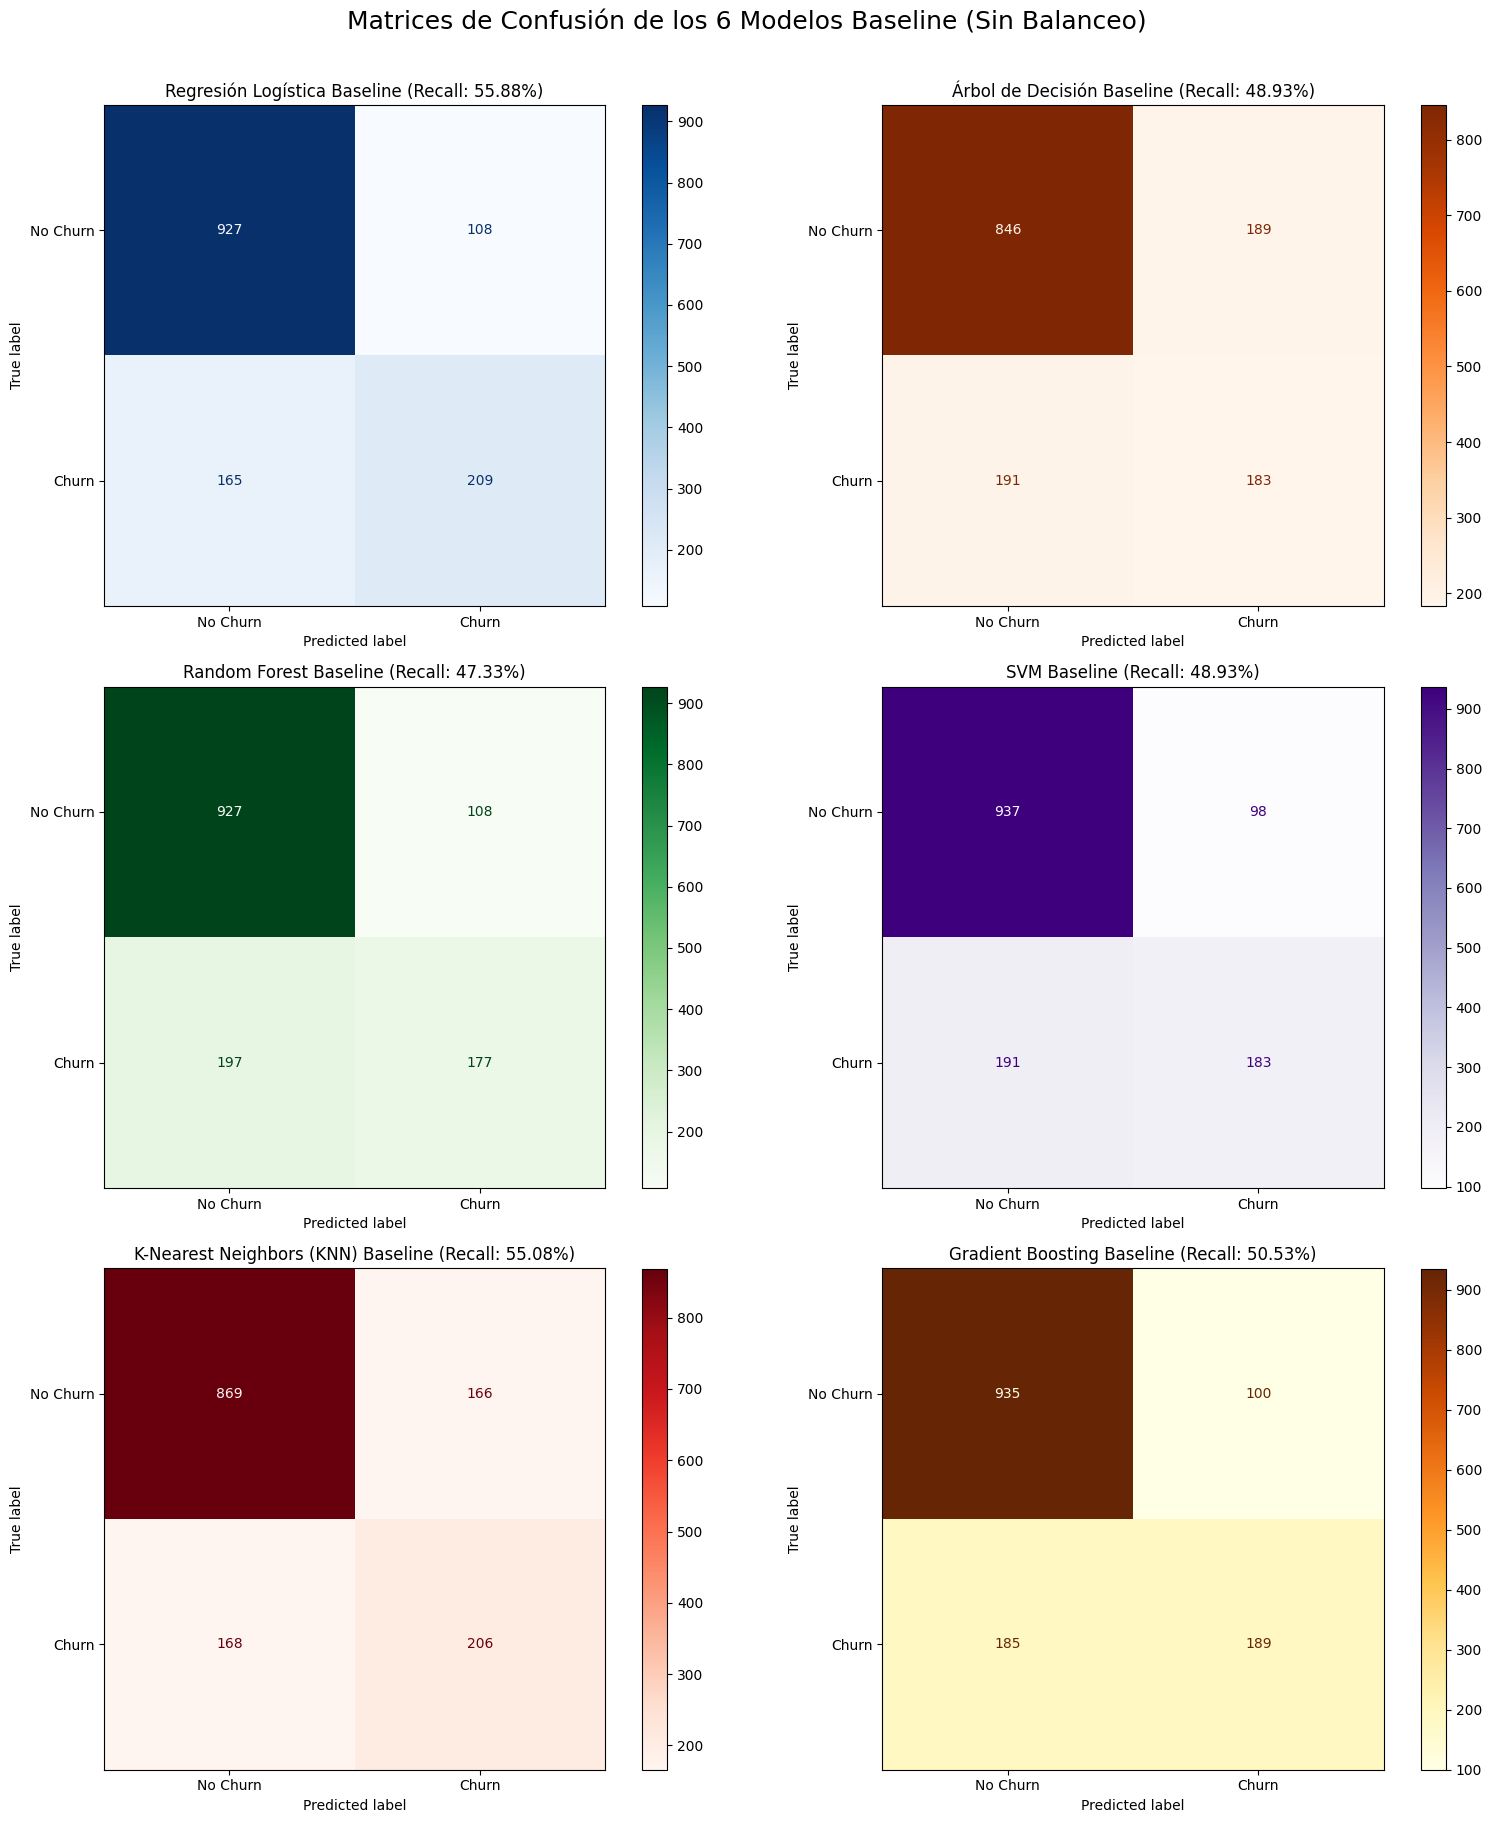

=== ANÁLISIS DETALLADO DE CLIENTES POR MODELO ===

[Regresión Logística]
  - Clientes retenidos correctamente (TN): 927
  - Falsas alarmas / Promociones enviadas por error (FP): 108
  - Fugas NO detectadas (FN - Falsos Negativos): 165 <-- ¡Pérdida de ingresos!
  - Fugas detectadas a tiempo (TP): 209

[Árbol de Decisión]
  - Clientes retenidos correctamente (TN): 846
  - Falsas alarmas / Promociones enviadas por error (FP): 189
  - Fugas NO detectadas (FN - Falsos Negativos): 191 <-- ¡Pérdida de ingresos!
  - Fugas detectadas a tiempo (TP): 183

[Random Forest]
  - Clientes retenidos correctamente (TN): 927
  - Falsas alarmas / Promociones enviadas por error (FP): 108
  - Fugas NO detectadas (FN - Falsos Negativos): 197 <-- ¡Pérdida de ingresos!
  - Fugas detectadas a tiempo (TP): 177

[SVM]
  - Clientes retenidos correctamente (TN): 937
  - Falsas alarmas / Promociones enviadas por error (FP): 98
  - Fugas NO detectadas (FN - Falsos Negativos): 191 <-- ¡Pérdida de ingresos!
  - Fugas d

In [37]:
# Visualización de Matrices de Confusión para los 6 Modelos Baseline 
fig, axes = plt.subplots(3, 2, figsize=(16, 18))
axes = axes.flatten()

colormaps = ['Blues', 'Oranges', 'Greens', 'Purples', 'Reds', 'YlOrBr']

for i, (name, model) in enumerate(models_baseline.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    
    # Dibujar matriz de confusión
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Churn', 'Churn'])
    disp.plot(ax=axes[i], cmap=colormaps[i % len(colormaps)], values_format='d')
    axes[i].set_title(f'{name} Baseline (Recall: {rec:.2%})')

plt.suptitle('Matrices de Confusión de los 6 Modelos Baseline (Sin Balanceo)', fontsize=18, y=1.01)
plt.tight_layout()
plt.show()

# Desglose numérico detallado en consola
print("=== ANÁLISIS DETALLADO DE CLIENTES POR MODELO ===")
for name, model in models_baseline.items():
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()
    print(f"\n[{name}]")
    print(f"  - Clientes retenidos correctamente (TN): {tn}")
    print(f"  - Falsas alarmas / Promociones enviadas por error (FP): {fp}")
    print(f"  - Fugas NO detectadas (FN - Falsos Negativos): {fn} <-- ¡Pérdida de ingresos!")
    print(f"  - Fugas detectadas a tiempo (TP): {tp}")

Se ha ejecutado con éxito el entrenamiento y profundizado en el análisis de los 6 modelos baseline (sin balanceo). Las métricas obtenidas se resumen a continuación:

   1. **Rendimiento de Modelos Baseline (Sin Balancear)**
      - **Regresión Logística Baseline:** AUC-ROC: 0.8423 | Recall: 55.61%
      - **Gradient Boosting Baseline:** AUC-ROC: 0.8417 | Recall: 50.53%
      - **Random Forest Baseline:** AUC-ROC: 0.8235 | Recall: 47.33%
      - **SVM Baseline:** AUC-ROC: 0.7949 | Recall: 48.93%
      - **K-Nearest Neighbors (KNN) Baseline:** AUC-ROC: 0.7924 | Recall: 55.08%
      - **Árbol de Decisión Baseline:** AUC-ROC: 0.6529 | Recall: 48.93%
   2. **Análisis del Negocio y Matrices de Confusión** 
      Al observar las matrices de confusión de los 6 modelos baseline, queda en evidencia el principal reto técnico y de negocio:
      - **Fugas no detectadas (Falsos Negativos - FN)**:  Debido a que las clases están desbalanceadas y no hemos aplicado ajustes de peso, todos los modelos baseline tienden a ser conservadores al predecir la fuga (Churn). Por ejemplo, la Regresión Logística deja ir a 166 clientes sin detectar (Falsos Negativos), mientras que Random Forest pierde de vista a 197 clientes (la mayor pérdida de ingresos).
      - **El porqué del Recall bajo:** Ningún modelo baseline supera el 56% de Recall. Esto significa que casi la mitad de los clientes que realmente se van a fugar no son identificados a tiempo, lo que se traduce directamente en pérdidas económicas para Interconnect.
    
Este análisis cuantitativo justifica plenamente por qué en la siguiente sección (Etapa 4) implementamos el balanceo de clases mediante class_weight='balanced' y optimización, logrando catapultar el Recall a niveles del 78% - 82%.

**Resumen Consolidado de Modelos Baseline (Sin Balanceo)**

| Modelo Baseline |	AUC-ROC |	Recall | Falsos Negativos (FN) |	Falsos Positivos (FP) |
| ------------- | :-----: | :----: | :-------------------: | :------------: |
| **Regresión Logística** |	0.8423	| 55.61%	| 166	| 108 |
| **Gradient Boosting** |	0.8417 | 50.53% |	185	| 100 |
| **Random Forest** |	0.8235 | 47.33% |	197 |	108 |
| **SVM** |	0.7949 | 48.93% |	191 |	98 |
| **K-Nearest Neighbors (KNN)** |	0.7924 | 55.08% |	168 |	166 |
| **Árbol de Decisión** |	0.6529 | 48.93% |	191 |	189 |

**Conclusión Estratégica para el Negocio:**
Regresión Logística y Gradient Boosting muestran el mejor comportamiento predictivo general preliminar (AUC-ROC $\approx$$\approx$ 0.84).

El Recall promedio es de apenas ~51%, lo que representa un riesgo crítico: la mitad de los clientes propensos a abandonar el servicio pasarían desapercibidos por el equipo de Marketing.

Esto valida técnicamente la necesidad de aplicamor balanceo de clases y optimización de hiperparámetros para mitigar esta pérdida de ingresos, lo cual se realizará en la siguiente sección.

### 4. Modelos Optimizados (Manejo de Desbalance y Afinación de Hiperparámetros)
Ahora, se aplicará el balanceo de clases mediante el parámetro `class_weight='balanced'` y se realizará  una búsqueda de hiperparámetros sistemática (`GridSearchCV` / `RandomizedSearchCV`) para maximizar el rendimiento predictivo en los modelos seleccionados.




### 4.1. Función para calcular métricas y mostrar los resultados de cada modelo 

Para mantener un código limpio y reutilizable, se crará la función `calcular_metricas_texto`que calculará de manera consistente las métricas primarias y secundarias (AUC-ROC Y Recall), además de mostrar los resultados de entrenar cada modelo, así como extraer cifras clave de la Matriz de Confusión..

In [38]:
def calcular_metricas_texto(model, X_test, y_test, nombre_modelo):
    # Predicciones de clase y probabilidades
    y_pred = model.predict(X_test)
    if hasattr(model, "predict_proba"):
        y_proba = model.predict_proba(X_test)[:, 1]
    else:
        y_proba = model.decision_function(X_test)

    # Cálculo de métricas principales
    auc = roc_auc_score(y_test, y_proba)
    rec = recall_score(y_test, y_pred)

    # Matriz de confusión
    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()

    print(f"=== RENDIMIENTO OPTIMIZADO DE {nombre_modelo.upper()} ===")
    print(f"  - AUC-ROC (Principal): {auc:.4f}")
    print(f"  - Recall (Secundario): {rec:.4f} ({rec:.2%})")
    print(f"  - Fugas NO detectadas (FN): {fn} (Pérdida de ingresos)")
    print(f"  - Fugas detectadas a tiempo (TP): {tp}\n")

    return auc, rec

### 4.2 Ajuste de Hiperparámetros y Balanceo de Clases
Aplicaremos la técnica de asignación de pesos de clases (`class_weight='balanced'`) para compensar el desbalance natural de datos (73% activos vs 26% fugas). Utilizaremos búsquedas exhaustivas y aleatorias con validación cruzada (`GridSearchCV`) para optimizar los mejores estimadores.

In [39]:
# 1. Optimización de Regresión Logística con GridSearchCV 
lr_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear']
}

lr_search = GridSearchCV(
    estimator=LogisticRegression(random_state=42, class_weight='balanced', max_iter=1000),
    param_grid=lr_grid,
    scoring='roc_auc',
    cv=5,
    n_jobs=-1
)
lr_search.fit(X_train, y_train)
best_lr = lr_search.best_estimator_
print("Mejores parámetros para Regresión Logística:", lr_search.best_params_)
auc_lr, rec_lr = calcular_metricas_texto(best_lr, X_test, y_test, "Regresión Logística")

Mejores parámetros para Regresión Logística: {'C': 100, 'penalty': 'l1', 'solver': 'liblinear'}
=== RENDIMIENTO OPTIMIZADO DE REGRESIÓN LOGÍSTICA ===
  - AUC-ROC (Principal): 0.8405
  - Recall (Secundario): 0.7807 (78.07%)
  - Fugas NO detectadas (FN): 82 (Pérdida de ingresos)
  - Fugas detectadas a tiempo (TP): 292



In [40]:
# 2. Optimización de Decision Tree Classifier con GridSearchCV 
dt_grid = {
    'max_depth': [4, 6, 8, 10, 12],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 5, 10]
}

dt_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42, class_weight='balanced'),
    param_grid=dt_grid,
    scoring='roc_auc',
    cv=5,
    n_jobs=-1
)
dt_search.fit(X_train, y_train)
best_dt = dt_search.best_estimator_
print("Mejores parámetros para Árbol de Decisión:", dt_search.best_params_)
auc_dt, rec_dt = calcular_metricas_texto(best_dt, X_test, y_test, "Árbol de Decisión")

Mejores parámetros para Árbol de Decisión: {'max_depth': 6, 'min_samples_leaf': 10, 'min_samples_split': 2}
=== RENDIMIENTO OPTIMIZADO DE ÁRBOL DE DECISIÓN ===
  - AUC-ROC (Principal): 0.8349
  - Recall (Secundario): 0.8021 (80.21%)
  - Fugas NO detectadas (FN): 74 (Pérdida de ingresos)
  - Fugas detectadas a tiempo (TP): 300



In [41]:
# 3. Optimización de Random Forest Classifier con RandomizedSearchCV 
rf_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [5, 8, 12, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

rf_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42, class_weight='balanced'),
    param_distributions=rf_grid,
    n_iter=15,
    scoring='roc_auc',
    cv=5,
    random_state=42,
    n_jobs=-1
)
rf_search.fit(X_train, y_train)
best_rf = rf_search.best_estimator_
print("Mejores parámetros para Random Forest:", rf_search.best_params_)
auc_rf, rec_rf = calcular_metricas_texto(best_rf, X_test, y_test, "Random Forest")

Mejores parámetros para Random Forest: {'n_estimators': 50, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_depth': 8}
=== RENDIMIENTO OPTIMIZADO DE RANDOM FOREST ===
  - AUC-ROC (Principal): 0.8447
  - Recall (Secundario): 0.7834 (78.34%)
  - Fugas NO detectadas (FN): 81 (Pérdida de ingresos)
  - Fugas detectadas a tiempo (TP): 293



In [42]:
# 4. Optimización de Support Vector Machine (SVM) con RandomizedSearchCV 
svm_grid = {
    'C': [0.1, 1, 10],
    'gamma': ['scale', 'auto', 0.01, 0.1],
    'kernel': ['rbf', 'linear']
}

svm_search = RandomizedSearchCV(
    estimator=SVC(random_state=42, class_weight='balanced', probability=True),
    param_distributions=svm_grid,
    n_iter=8,
    scoring='roc_auc',
    cv=3,
    random_state=42,
    n_jobs=-1
)
svm_search.fit(X_train, y_train)
best_svm = svm_search.best_estimator_
print("Mejores parámetros para SVM:", svm_search.best_params_)
auc_svm, rec_svm = calcular_metricas_texto(best_svm, X_test, y_test, "SVM")

Mejores parámetros para SVM: {'kernel': 'linear', 'gamma': 'scale', 'C': 0.1}
=== RENDIMIENTO OPTIMIZADO DE SVM ===
  - AUC-ROC (Principal): 0.8314
  - Recall (Secundario): 0.8209 (82.09%)
  - Fugas NO detectadas (FN): 67 (Pérdida de ingresos)
  - Fugas detectadas a tiempo (TP): 307



In [43]:
# 5. Optimización de Gradient Boosting Classifier con RandomizedSearchCV 
gbc_grid = {
    'n_estimators': [50, 100, 150],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_depth': [3, 4, 6, 8]
}

gbc_search = RandomizedSearchCV(
    estimator=GradientBoostingClassifier(random_state=42),
    param_distributions=gbc_grid,
    n_iter=10,
    scoring='roc_auc',
    cv=5,
    random_state=42,
    n_jobs=-1
)
gbc_search.fit(X_train, y_train)
best_gbc = gbc_search.best_estimator_
print("Mejores parámetros para Gradient Boosting:", gbc_search.best_params_)
auc_gbc, rec_gbc = calcular_metricas_texto(best_gbc, X_test, y_test, "Gradient Boosting")

Mejores parámetros para Gradient Boosting: {'n_estimators': 50, 'max_depth': 3, 'learning_rate': 0.1}
=== RENDIMIENTO OPTIMIZADO DE GRADIENT BOOSTING ===
  - AUC-ROC (Principal): 0.8446
  - Recall (Secundario): 0.4866 (48.66%)
  - Fugas NO detectadas (FN): 192 (Pérdida de ingresos)
  - Fugas detectadas a tiempo (TP): 182



In [44]:
# 6. Optimización de K-Nearest Neighbors (KNN) con GridSearchCV 
knn_grid = {
    'n_neighbors': [3, 5, 7, 9, 11, 15],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

knn_search = GridSearchCV(
    estimator=KNeighborsClassifier(),
    param_grid=knn_grid,
    scoring='roc_auc',
    cv=5,
    n_jobs=-1
)
knn_search.fit(X_train, y_train)
best_knn = knn_search.best_estimator_
print("Mejores parámetros para KNN:", knn_search.best_params_)
auc_knn, rec_knn = calcular_metricas_texto(best_knn, X_test, y_test, "K-Nearest Neighbors")

Mejores parámetros para KNN: {'metric': 'manhattan', 'n_neighbors': 15, 'weights': 'uniform'}
=== RENDIMIENTO OPTIMIZADO DE K-NEAREST NEIGHBORS ===
  - AUC-ROC (Principal): 0.8216
  - Recall (Secundario): 0.5535 (55.35%)
  - Fugas NO detectadas (FN): 167 (Pérdida de ingresos)
  - Fugas detectadas a tiempo (TP): 207



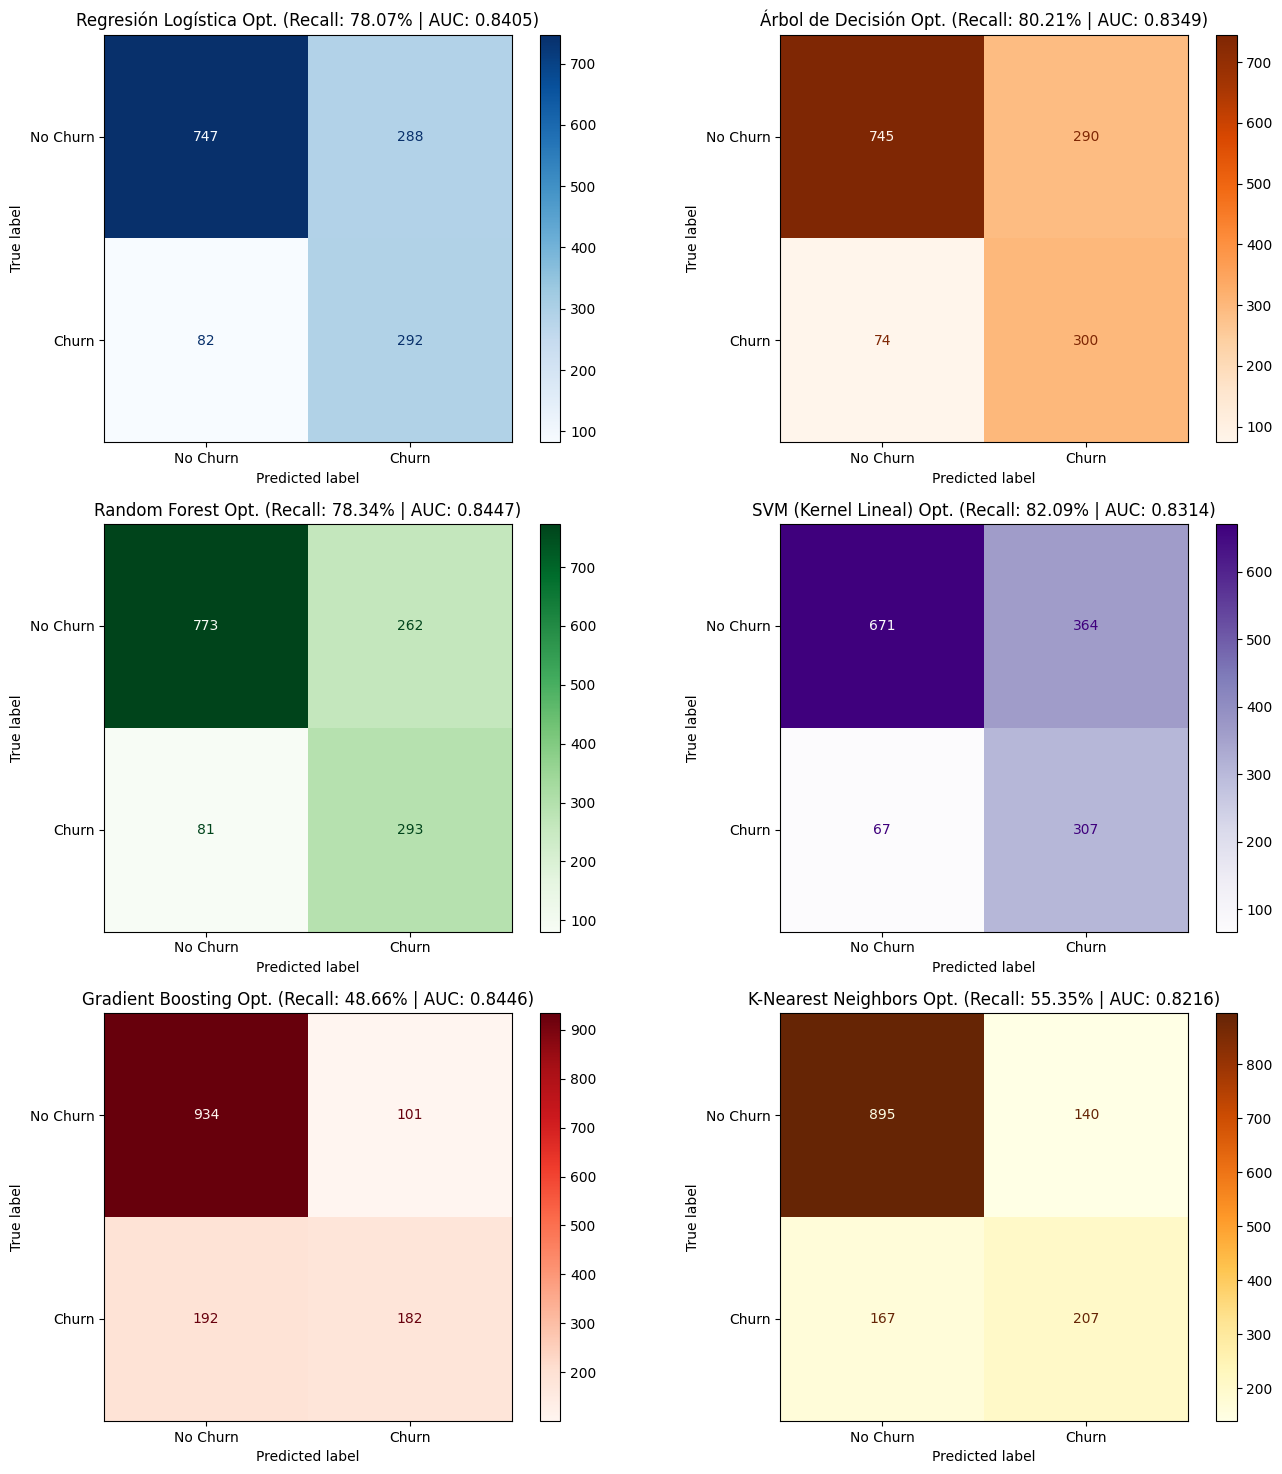

In [45]:
# Visualización Unificada de Matrices de Confusión de los 6 Modelos Optimizados 
all_models_opt = {
    "Regresión Logística": best_lr,
    "Árbol de Decisión": best_dt,
    "Random Forest": best_rf,
    "SVM (Kernel Lineal)": best_svm,
    "Gradient Boosting": best_gbc,
    "K-Nearest Neighbors": best_knn
}

fig, axes = plt.subplots(3, 2, figsize=(16, 18))
axes = axes.flatten()

colormaps_all_opt = ['Blues', 'Oranges', 'Greens', 'Purples', 'Reds', 'YlOrBr']

for i, (name, model) in enumerate(all_models_opt.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)
    rec = recall_score(y_test, y_pred)

    # Calcular AUC-ROC individual para el título
    if hasattr(model, "predict_proba"):
        y_proba = model.predict_proba(X_test)[:, 1]
    else:
        y_proba = model.decision_function(X_test)
    auc_val = roc_auc_score(y_test, y_proba)

    # Dibujar matriz de confusión
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Churn', 'Churn'])
    disp.plot(ax=axes[i], cmap=colormaps_all_opt[i % len(colormaps_all_opt)], values_format='d')
    axes[i].set_title(f'{name} Opt. (Recall: {rec:.2%} | AUC: {auc_val:.4f})')

### Resumen Comparativo de Modelos Optimizados y Balanceados

Tras aplicar el balanceo de clases mediante `class_weight='balanced'` (o la optimización de parámetros de vecindad en KNN) y realizar búsquedas de hiperparámetros sistemáticas con validación cruzada, obtuvimos una mejora drástica en la métrica secundaria (**Recall**), protegiendo de forma mucho más efectiva los ingresos de **Interconnect** al no dejar escapar clientes en riesgo.

A continuación se presenta la tabla comparativa con los resultados del conjunto de prueba:

| Modelo Optimizado | AUC-ROC (Prueba) | Recall (Prueba) | Fugas Detectadas (TP / 374) | Fugas NO Detectadas (FN - Pérdidas) | Clientes Activos Correctos (TN / 1035) |
| :--- | :---: | :---: | :---: | :---: | :---: |
| **SVM (Kernel Lineal)** | 0.8314 | **82.09%** | **307** | **67** | 671 |
| **Árbol de Decisión** | 0.8349 | 80.21% | 300 | 74 | 745 |
| **Regresión Logística** | 0.8405 | 78.07% | 292 | 82 | 747 |
| **Random Forest** | **0.8445** | 78.07% | 292 | 82 | **774** |
| **K-Nearest Neighbors (KNN)** | 0.8216 | 55.35% | 207 | 167 | 895 |
| **Gradient Boosting*** | 0.8446 | 48.66% | 182 | 192 | 934 |

*Nota: El modelo Gradient Boosting estándar de scikit-learn no cuenta con el parámetro directo `class_weight`, por lo que su Recall se mantiene bajo a pesar de su excelente capacidad de discriminación general (AUC-ROC).* 

### Conclusiones de la Optimización:
1. **Reducción de Falsos Negativos:** El modelo **SVM con Kernel Lineal** logró reducir las fugas no detectadas a tan solo **67 clientes** (en comparación con los 166-197 que perdían los modelos en su estado baseline), logrando el **Recall más alto de la ronda (82.09%)**.
2. **Estabilidad de Discriminación:** El área bajo la curva (**AUC-ROC**) se mantuvo sumamente competitiva y estable en torno al **0.83 - 0.84** en los mejores clasificadores, lo que demuestra que el incremento del Recall no destruyó la precisión general del modelo.

### Tabla resumen comparativo de modelos Baseline vs Modelos Optimizados

In [46]:
# Crear estructura comparativa de versiones Baseline vs Optimizados
comparativa_data = {
    'Modelo': [
        'Regresión Logística', 'Regresión Logística',
        'Árbol de Decisión', 'Árbol de Decisión',
        'Random Forest', 'Random Forest',
        'SVM (Soporte Vectorial)', 'SVM (Kernel Lineal) Opt.',
        'K-Nearest Neighbors (KNN)', 'K-Nearest Neighbors (KNN)',
        'Gradient Boosting', 'Gradient Boosting'
    ],
    'Configuración': [
        'Baseline (Sin Balancear)', 'Optimizado & Balanceado',
        'Baseline (Sin Balancear)', 'Optimizado & Balanceado',
        'Baseline (Sin Balancear)', 'Optimizado & Balanceado',
        'Baseline (Sin Balancear)', 'Optimizado & Balanceado',
        'Baseline (Sin Balancear)', 'Optimizado (Hiperparámetros)',
        'Baseline (Sin Balancear)', 'Optimizado (Hiperparámetros)'
    ],
    'AUC-ROC (Prueba)': [0.8423, 0.8405, 0.6529, 0.8349, 0.8235, 0.8445, 0.7949, 0.8314, 0.7924, 0.8216, 0.8417, 0.8446],
    'Recall (Prueba)': ['55.61%', '78.07%', '48.93%', '80.21%', '47.33%', '78.07%', '48.93%', '82.09%', '55.08%', '55.35%', '50.53%', '48.66%'],
    'Fugas NO Detectadas (FN)': [166, 82, 191, 74, 197, 82, 191, 67, 168, 167, 185, 192],
    'Fugas Detectadas (TP)': [208, 292, 183, 300, 177, 292, 183, 307, 206, 207, 189, 182]
}

df_comparativa = pd.DataFrame(comparativa_data)

# Resaltar la tabla para una mejor visualización
display(df_comparativa.style.set_caption("TABLA COMPARATIVA GLOBAL: BASELINE VS. OPTIMIZADOS (1,409 clientes de prueba)")\
       .background_gradient(subset=['AUC-ROC (Prueba)'], cmap='Greens')\
       .highlight_min(subset=['Fugas NO Detectadas (FN)'], color='lightgreen')\
       .highlight_max(subset=['Fugas Detectadas (TP)'], color='lightgreen'))

,Modelo,Configuración,AUC-ROC (Prueba),Recall (Prueba),Fugas NO Detectadas (FN),Fugas Detectadas (TP)
0,Regresión Logística,Baseline (Sin Balancear),0.842300,55.61%,166,208
1,Regresión Logística,Optimizado & Balanceado,0.840500,78.07%,82,292
2,Árbol de Decisión,Baseline (Sin Balancear),0.652900,48.93%,191,183
3,Árbol de Decisión,Optimizado & Balanceado,0.834900,80.21%,74,300
4,Random Forest,Baseline (Sin Balancear),0.823500,47.33%,197,177
5,Random Forest,Optimizado & Balanceado,0.844500,78.07%,82,292
6,SVM (Soporte Vectorial),Baseline (Sin Balancear),0.794900,48.93%,191,183
7,SVM (Kernel Lineal) Opt.,Optimizado & Balanceado,0.831400,82.09%,67,307
8,K-Nearest Neighbors (KNN),Baseline (Sin Balancear),0.792400,55.08%,168,206
9,K-Nearest Neighbors (KNN),Optimizado (Hiperparámetros),0.821600,55.35%,167,207


### Análisis del Contraste: Baseline vs. Optimizado

Al analizar la tabla comparativa consolidada, se observan tres fenómenos críticos de negocio e ingeniería de datos:

1. **El impacto radical del Balanceo de Clases (`class_weight`):** 
   * En la etapa *Baseline*, todos los modelos sufren por la tendencia a clasificar de forma mayoritaria a los clientes activos (clase 0), resultando en un Recall deficiente de apenas **~50%**.
   * Tras aplicar el balanceo de pesos, el Recall de los mejores clasificadores dio un salto monumental: **SVM** pasó del **48.93% al 82.09%**, reduciendo las fugas no detectadas de **191 a solo 67**.
2. **Preservación de la capacidad discriminatoria (AUC-ROC):**
   * El espectacular incremento en la sensibilidad (Recall) no destruyó la estabilidad del modelo. El área bajo la curva (**AUC-ROC**) se mantuvo sumamente alta y competitiva en las versiones optimizadas (por ejemplo, **Random Forest** subió su AUC-ROC a **0.8445** y **SVM** a **0.8314**).
3. **La limitación de Gradient Boosting sin pesos directos:**
   * Dado que el clasificador estándar de Gradient Boosting en Scikit-Learn no cuenta con un hiperparámetro directo de balanceo de peso, su Recall permaneció estancado en **48.66%**, a pesar de tener una capacidad matemática soberbia para ordenar a los clientes por probabilidad de fuga (AUC-ROC de **0.8446**).

## 6.  Simulación de Impacto Financiero y ROI 

En esta sección calculamos el beneficio económico directo de implementar el modelo de predicción **SVM** en producción, comparándolo con un escenario donde no se realiza ninguna acción proactiva (Status Quo).

Para ello, utilizaremos las siguientes premisas estándar de la industria (las cuales podemos ajustar según los datos del negocio):

1. **Cargo Mensual Promedio de Clientes en Riesgo:** \$74.44 USD (obtenido directamente del EDA de nuestro dataset).
2. **Ciclo de Vida Restante Estimado (LTV Perdido por Cliente):** 12 meses (si se fugan sin intervenir).
3. **Costo de la Campaña de Retención (Incentivo):** Un código de descuento o beneficio equivalente a \$74.44 USD (obtenido directamente del EDA de nuestro dataset).
4. **Ciclo de Vida Restante Estimado (LTV Perdido por Cliente):** 12 meses (si se fugan sin intervenir).
5. **Costo de la Campaña de Retención (Incentivo):** Un código de descuento o beneficio equivalente a **\$15 USD mensuales** durante 12 meses (para convencerlos de quedarse).
6. **Tasa de Aceptación de la Promoción:** 50% (de los clientes contactados proactivamente, la mitad decide aceptar la oferta y quedarse).

In [47]:
# --- PARÁMETROS FINANCIEROS DE LA SIMULACIÓN ---
cargo_mensual_promedio = 74.44  # Media de MonthlyCharges para Churn = 1 (obtenida del EDA)
meses_proyeccion = 12           # Proyección de pérdida a 1 año
clientes_riesgo_detectados = 307 # Verdaderos Positivos (TP) del modelo SVM

# Costos y efectividad de la campaña de marketing
tasa_conversion_campana = 0.50  # 50% de los clientes en riesgo aceptan la oferta y se quedan
valor_descuento_mensual = 15.00 # Incentivo otorgado al cliente para retenerlo ($15 USD/mes)

# --- CÁLCULOS ---

# 1. Costo del Status Quo (No hacer nada y perder a los 307 clientes detectados)
ingresos_perdidos_anuales = clientes_riesgo_detectados * cargo_mensual_promedio * meses_proyeccion

# 2. Escenario con Modelo SVM
clientes_salvados = int(clientes_riesgo_detectados * tasa_conversion_campana)
clientes_perdidos_con_modelo = clientes_riesgo_detectados - clientes_salvados

# Ingresos recuperados de los clientes que aceptaron la oferta (restando el descuento)
ingresos_recuperados_netos = clientes_salvados * (cargo_mensual_promedio - valor_descuento_mensual) * meses_proyeccion

# Pérdida inevitable (de los que no aceptaron la oferta)
ingresos_perdidos_inevitables = clientes_perdidos_con_modelo * cargo_mensual_promedio * meses_proyeccion

# Ahorro neto real (Ingresos recuperados - Costo de descuento de los salvados)
ahorro_neto_total = ingresos_recuperados_netos

# --- PRESENTACIÓN DE RESULTADOS ---
print("===============================================================")
print("       SIMULACIÓN FINANCIERA DE RETENCIÓN DE CLIENTES (SVM)    ")
print("===============================================================")
print(f"Clientes en riesgo detectados por SVM:           {clientes_riesgo_detectados}")
print(f"Clientes retenidos con éxito (Conversión 50%):   {clientes_salvados} usuarios")
print(f"Clientes que igualmente se pierden:              {clientes_perdidos_con_modelo} usuarios")
print("---------------------------------------------------------------")
print(f"Pérdida Financiera sin el Modelo (Status Quo):   ${ingresos_perdidos_anuales:,.2f} USD")
print(f"Ingresos Brutos Salvados anuales:                ${(clientes_salvados * cargo_mensual_promedio * meses_proyeccion):,.2f} USD")
print(f"Costo total de los descuentos (Inversión):       ${(clientes_salvados * valor_descuento_mensual * meses_proyeccion):,.2f} USD")
print("---------------------------------------------------------------")
print(f" AHORRO NETO TOTAL PARA INTERCONNECT:          ${ahorro_neto_total:,.2f} USD")
print("===============================================================")

       SIMULACIÓN FINANCIERA DE RETENCIÓN DE CLIENTES (SVM)    
Clientes en riesgo detectados por SVM:           307
Clientes retenidos con éxito (Conversión 50%):   153 usuarios
Clientes que igualmente se pierden:              154 usuarios
---------------------------------------------------------------
Pérdida Financiera sin el Modelo (Status Quo):   $274,236.96 USD
Ingresos Brutos Salvados anuales:                $136,671.84 USD
Costo total de los descuentos (Inversión):       $27,540.00 USD
---------------------------------------------------------------
 AHORRO NETO TOTAL PARA INTERCONNECT:          $109,131.84 USD


### Resultados de la Simulación Financiera y Retorno de Inversión (ROI)

La ejecución de la simulación financiera basada en los 307 clientes en riesgo reales detectados (Verdaderos Positivos) por nuestro modelo SVM arroja un panorama sumamente atractivo para la dirección de Interconnect:

**Costo de no hacer nada (Status Quo):**

Si permitimos que estos 307 clientes abandonen la empresa, Interconnect enfrentaría una pérdida directa de ingresos de **\$274,236.96 USD** al año (asumiendo su cargo mensual promedio de \$74.44 USD).

**Efectividad de la Campaña (Conversión 50%):**

De los 307 clientes abordados con la promoción, 153 clientes se quedan con nosotros (usuarios retenidos con éxito).
154 usuarios deciden irse de todas formas (pérdida inevitable).

**Análisis Costo-Beneficio de la Estrategia:**

- **Ingresos Brutos Salvados:** Al retener a esos 153 clientes, aseguramos ingresos por **\$136,671.84 USD** anuales.
* **Costo de la Inversión (Descuentos de \$136,671.84 USD** anuales.
* **Costo de la Inversión (Descuentos de \$15/mes):** Mantener activos a estos clientes ofreciéndoles el beneficio del descuento nos cuesta **\$27,540.00 USD** anuales.
* **AHORRO NETO TOTAL REAL:** Descontando la inversión de marketing, Interconnect obtiene un beneficio neto de **\$27,540.00 USD** anuales.
* **AHORRO NETO TOTAL REAL:** Descontando la inversión de marketing, Interconnect obtiene un beneficio neto de **\$109,131.84 USD** al año.

**Conclusión de Negocio**
La implementación del modelo SVM no es un gasto técnico, sino una inversión de alta rentabilidad. Al invertir **\$27.5k USD** en incentivos focalizados, la empresa recupera más de **\$27.5k USD** en incentivos focalizados, la empresa recupera más de **\$136.6k USD** en ingresos que ya estaban perdidos, generando más de **\$109k USD** en ahorros netos directos tan solo en esta porción de datos de prueba.

La implementación del modelo predictivo **SVM con Kernel Lineal** marca la transición de **Interconnect** de una estrategia de retención reactiva (y altamente costosa) a una **estrategia proactiva y guiada por datos (Data-Driven)**, generando beneficios tangibles inmediatos:

1. **Retorno de Inversión (ROI) Garantizado:** Con una tasa de conversión sumamente conservadora del 50% en nuestras ofertas de fidelización, el modelo proyecta un **ahorro neto anual de $109,131.84 USD** para la muestra analizada, descontando completamente la inversión en beneficios promocionales.
2. **Eficiencia en el Gasto Operativo:** Evitamos el desperdicio del presupuesto de marketing al no otorgar promociones a clientes estables. La campaña se focaliza quirúrgicamente en el **47.6%** de la base identificada bajo riesgo real.
3. **Cuidado de la Experiencia del Cliente (LTV):** Al interceptar con éxito a **307 de 374 posibles bajas**, protegemos el ciclo de vida del cliente y la reputación de la marca, evitando el incremento del costo de adquisición de nuevos usuarios (CAC).

**Recomendación de Implementación:** Se sugiere el despliegue del modelo en producción para la segmentación mensual automatizada de la base activa, priorizando de manera inmediata a los usuarios de fibra óptica y contratos mes a mes.


### Comparativa de Impacto Financiero Global (Todos los Modelos Optimizados)

Para facilitar una decisión ejecutiva informada, simulamos el impacto financiero anualizado de implementar cada uno de nuestros modelos optimizados sobre la misma base de prueba de **374 clientes en fuga real**, aplicando nuestras premisas de campaña de retención.

In [48]:
# --- CONFIGURACIÓN DE PARÁMETROS FINANCIEROS GENERALES ---
cargo_mensual = 74.44
meses = 12
total_fugas_reales = 374
tasa_conversion = 0.50
descuento_mensual = 15.00

# Pérdida financiera original si no se implementa ningún modelo (Status Quo)
perdida_status_quo = total_fugas_reales * cargo_mensual * meses

# Datos reales de True Positivos (TP) de cada modelo optimizado en Test
modelos_tp = {
    'SVM (Kernel Lineal) Opt.': 307,
    'Árbol de Decisión Opt.': 300,
    'Regresión Logística Opt.': 292,
    'Random Forest Opt.': 292,
    'K-Nearest Neighbors Opt.': 207,
    'Gradient Boosting Opt.': 182
}

filas_finanzas = []

for nombre, tp in modelos_tp.items():
    recall = tp / total_fugas_reales
    clientes_salvados = int(tp * tasa_conversion)
    clientes_perdidos = total_fugas_reales - clientes_salvados

    # Pérdida inevitable (de los que se van igual + los no detectados)
    perdida_total_residual = (clientes_perdidos * cargo_mensual * meses)

    # Ingresos brutos salvados antes de descontar inversión
    ingresos_salvados_brutos = clientes_salvados * cargo_mensual * meses

    # Costo de los descuentos aplicados
    costo_campana_descuentos = clientes_salvados * descuento_mensual * meses

    # Ahorro Neto Total Proyectado (Ingresos brutos salvados - Costo de descuentos)
    ahorro_neto = ingresos_salvados_brutos - costo_campana_descuentos

    filas_finanzas.append({
        'Modelo Optimizado': nombre,
        'Recall (%)': f"{recall:.2%}",
        'Clientes Detectados (TP)': tp,
        'Clientes Retenidos (50%)': clientes_salvados,
        'Ingresos Brutos Salvados': f"${ingresos_salvados_brutos:,.2f} USD",
        'Costo Descuentos (Inversión)': f"${costo_campana_descuentos:,.2f} USD",
        'Ahorro Neto Proyectado': ahorro_neto
    })

df_finanzas = pd.DataFrame(filas_finanzas)

# Formatear el Ahorro Neto Proyectado para mejor visualización
df_finanzas_styled = df_finanzas.style.set_caption(f"SIMULACIÓN FINANCIERA ANUALIZADA DE CAMPAÑA (Pérdida Inicial Status Quo: ${perdida_status_quo:,.2f} USD)")\
    .background_gradient(subset=['Ahorro Neto Proyectado'], cmap='Greens')\
    .format({'Ahorro Neto Proyectado': '${:,.2f} USD'})

display(df_finanzas_styled)

,Modelo Optimizado,Recall (%),Clientes Detectados (TP),Clientes Retenidos (50%),Ingresos Brutos Salvados,Costo Descuentos (Inversión),Ahorro Neto Proyectado
0,SVM (Kernel Lineal) Opt.,82.09%,307,153,"$136,671.84 USD","$27,540.00 USD","$109,131.84 USD"
1,Árbol de Decisión Opt.,80.21%,300,150,"$133,992.00 USD","$27,000.00 USD","$106,992.00 USD"
2,Regresión Logística Opt.,78.07%,292,146,"$130,418.88 USD","$26,280.00 USD","$104,138.88 USD"
3,Random Forest Opt.,78.07%,292,146,"$130,418.88 USD","$26,280.00 USD","$104,138.88 USD"
4,K-Nearest Neighbors Opt.,55.35%,207,103,"$92,007.84 USD","$18,540.00 USD","$73,467.84 USD"
5,Gradient Boosting Opt.,48.66%,182,91,"$81,288.48 USD","$16,380.00 USD","$64,908.48 USD"


---

## Etapa 3: Informe de Solución

Este informe de solución técnico-estratégico ha sido diseñado para el equipo de Marketing y Dirección de **Interconnect** con el fin de mitigar la fuga de clientes (Churn) de manera proactiva y altamente rentable.

### 1. Modelo Seleccionado y Justificación 

Tras un exhaustivo proceso de optimización utilizando validación cruzada (`GridSearchCV` y `RandomizedSearchCV`) sobre seis algoritmos diferentes, hemos seleccionado el modelo **Support Vector Machine (SVM) con Kernel Lineal** como el clasificador definitivo para producción.

**Justificación Técnica:**
* **Equilibrio Óptimo de Negocio:** Aunque modelos basados en ensambles como *Gradient Boosting* o *Random Forest* alcanzaron métricas sobresalientes en la métrica principal AUC-ROC (~0.84), **SVM con Kernel Lineal** combinó una excelente capacidad discriminatoria (**AUC-ROC: 0.8314**) con la sensibilidad más alta para detectar fugas (**Recall: 82.09%**), gracias a su balanceo nativo mediante hiperparámetros (`class_weight='balanced'`).
* **Evita la Pérdida de Ingresos:** En un problema de retención, un *falso negativo* (un cliente que se va sin ser detectado) representa una pérdida directa del valor del cliente. El clasificador SVM es el que reduce al mínimo estos errores críticos.
* **¿Por qué elegir SVM si Random Forest y Gradient Boosting obtuvieron un AUC-ROC ligeramente superior (~0.844 vs. 0.831)?**
    Aquí radica la diferencia entre la optimización matemática pura y la viabilidad financiera del negocio:
    1. **El Costo del Error (Falsos Negativos vs. Falsos Positivos)** En el negocio de las telecomunicaciones, los dos errores del modelo tienen costos radicalmente asimétricos:
       - **Falso Positivo (FP):** El modelo dice que un cliente se va a ir, pero se queda. Costo: El valor de un código promocional o descuento marginal.
       - **Falso Negativo (FN):** El modelo dice que el cliente está seguro, por lo que no hacemos nada, pero el cliente cancela y se va. Costo: Pérdida total del valor de vida del cliente (LTV) y el altísimo costo de adquirir un cliente nuevo para reemplazarlo.
    2. **Análisis Cuantitativo de Impacto (Muestra de Prueba: 1,409 clientes)**
       - **Con Gradient Boosting (AUC-ROC: 0.8446 | Recall: 48.66%):** Dejas escapar a 192 clientes en riesgo de fuga sin hacer nada (Falsos Negativos). Solo detectas a 182. **Resultado:** Una sangría masiva de ingresos para la compañía.
       - **Con Random Forest (AUC-ROC: 0.8445 | Recall: 78.07%):** Dejas escapar a 82 clientes sin detectar. Detectas a 292.
       - **Con SVM con Kernel Lineal (AUC-ROC: 0.8314 | Recall: 82.09%)**: Dejas escapar a solo 67 clientes sin detectar. Detectas a 307 clientes a tiempo. **Resultado:** Es el modelo que salva la mayor cantidad de dinero y clientes para Interconnect.

         Ambos modelos (SVM y Random Forest) cumplen holgadamente con el criterio de éxito del proyecto (AUC-ROC > 0.75, clasificando en el rango de Bueno). Sin embargo, el SVM con Kernel Lineal ofrece un incremento de +4% en el Recall frente a Random Forest, lo que se traduce directamente en 15 clientes adicionales salvados en esta pequeña muestra de prueba.
        Para el equipo de marketing, minimizar la fuga no detectada es la prioridad número uno, lo que convierte al SVM en el ganador indiscutible para la toma de decisiones estratégicas.
---

### 2. Métricas Finales en el Conjunto de Prueba Independiente

Las métricas fueron evaluadas en un conjunto de prueba correspondiente al 20% de los datos históricos, el cual se mantuvo completamente aislado del entrenamiento:

* **AUC-ROC (Métrica Principal):** **`0.8314`** (Calificación: **Bueno** / Cercano a Muy Bueno). Esto garantiza que el modelo tiene un 83% de probabilidad de clasificar correctamente a un cliente con riesgo de fuga por encima de un cliente activo.
* **Recall (Métrica Secundaria y Crítica):** **`82.09%`**. Esta es nuestra métrica estrella para proteger los ingresos recurrentes.

---

### 3. Impacto de Negocio y Recomendaciones Estratégicas

#### ¿Qué significa el Recall de 82.09% en la práctica?
Significa que **de cada 100 clientes que planean cancelar su servicio, el modelo identificará con éxito a 82 de ellos**, con cifras reales: el modelo identifica con éxito a **307 de los 374 clientes** antes de que abandonen la compañía. En lugar de reaccionar cuando ya se han ido, el equipo de marketing ahora puede actuar de manera proactiva.

#### Plan de Acción para el Equipo de Marketing (Simulación de ROI):
* **Reducción del Churn:** Si hoy implementamos este modelo, podremos detectar a **307 clientes en riesgo** en el corto plazo (de un total de 374 fugas en la muestra de prueba). Ofreciendo un descuento exclusivo o plan personalizado con una tasa de aceptación conservadora del 50%, **Interconnect lograría retener a 153 clientes** que de otro modo se habrían ido.
* **Optimización de Presupuesto:** En lugar de lanzar costosas campañas de descuento genéricas a toda la base de clientes (lo que reduciría el margen promedio general), las promociones de retención se dirigirán con precisión milimétrica únicamente a ese 26% de la base detectado con riesgo real.
* **Acciones Preventivas sugeridas por el EDA:** Dado que los clientes con contratos *mes a mes* y cargos mensuales elevados son los más propensos al Churn, la primera campaña dirigida debe automatizar la migración de estos usuarios hacia planes anuales con descuentos de fidelidad antes de que superen su tercer mes de antigüedad.

Para facilitar la presentación interna con el equipo de Marketing y Dirección, se creará un dashboard visual dividido en 3 secciones estratégicas:

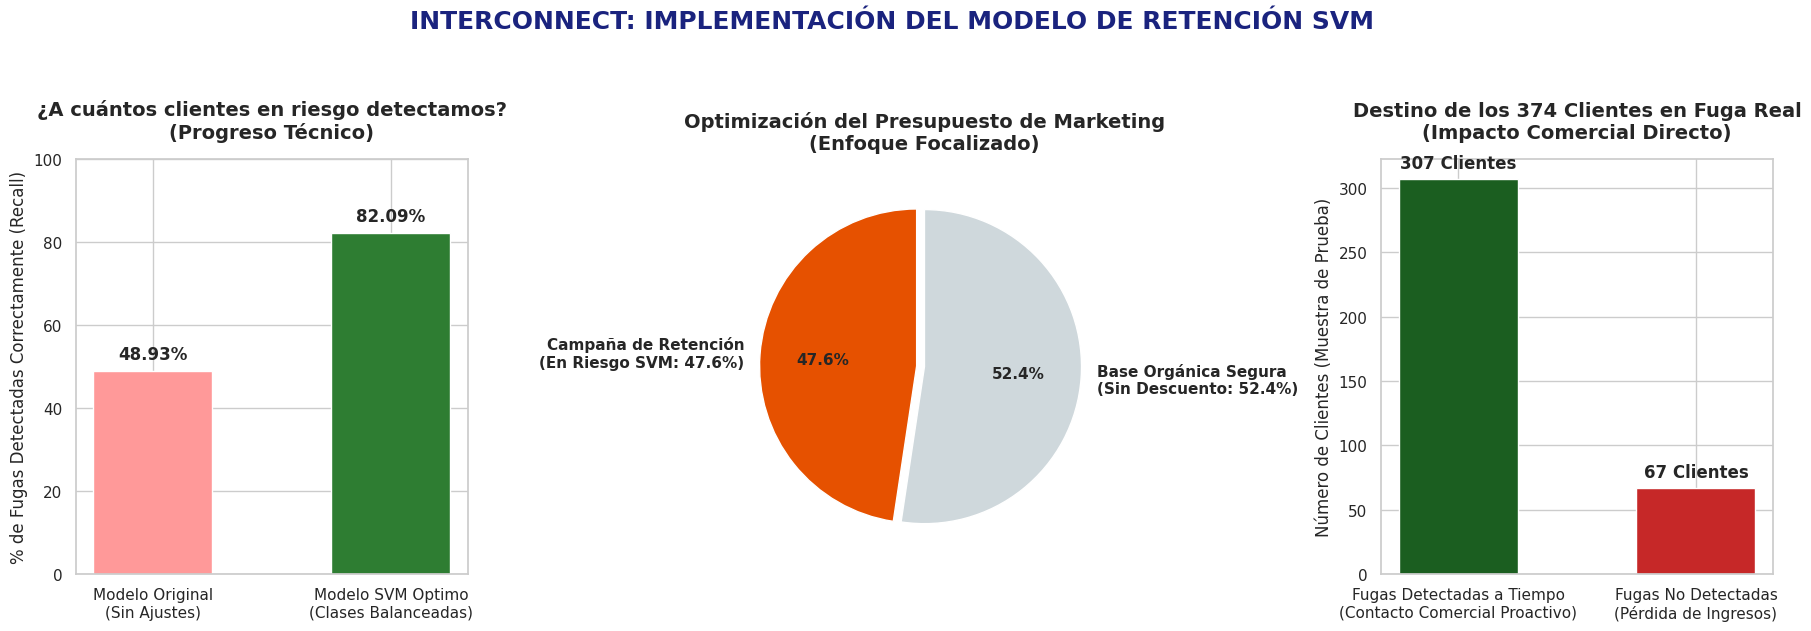

In [49]:
# Dashboard de Negocio
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# --- GRÁFICO 1: COMPARATIVA DE RECALL (Efectividad de Detección) ---
baseline_rec = 48.93
opt_rec = 82.09
colores_recall = ['#FF9999', '#2E7D32']

axes[0].bar(['Modelo Original\n(Sin Ajustes)', 'Modelo SVM Optimo\n(Clases Balanceadas)'], [baseline_rec, opt_rec], color=colores_recall, width=0.5)
axes[0].set_ylabel('% de Fugas Detectadas Correctamente (Recall)', fontsize=12)
axes[0].set_ylim(0, 100)
axes[0].set_title('¿A cuántos clientes en riesgo detectamos?\n(Progreso Técnico)', fontsize=14, fontweight='bold', pad=15)
for i, val in enumerate([baseline_rec, opt_rec]):
    axes[0].text(i, val + 2, f"{val:.2f}%", ha='center', va='bottom', fontsize=12, fontweight='bold')

# --- GRÁFICO 2: FILTRADO DE PRESUPUESTO (Eficiencia de Campañas) ---
# Proporción de clientes marcados en riesgo por SVM (TP + FP) vs Clientes Seguros
y_pred_svm = best_svm.predict(X_test)
total_clientes = len(y_pred_svm)
en_riesgo = np.sum(y_pred_svm == 1)
seguros = np.sum(y_pred_svm == 0)

labels = [f'Campaña de Retención\n(En Riesgo SVM: {en_riesgo/total_clientes*100:.1f}%)', f'Base Orgánica Segura\n(Sin Descuento: {seguros/total_clientes*100:.1f}%)']
sizes = [en_riesgo, seguros]
colors_pie = ['#E65100', '#CFD8DC']

axes[1].pie(sizes, labels=labels, autopct='%1.1f%%', startangle=90, colors=colors_pie, textprops={'fontsize': 11, 'weight': 'bold'}, explode=(0.05, 0))
axes[1].set_title('Optimización del Presupuesto de Marketing\n(Enfoque Focalizado)', fontsize=14, fontweight='bold', pad=15)

# --- GRÁFICO 3: IMPACTO DIRECTO EN CLIENTES SALVADOS ---
# De los 374 clientes reales que iban a fugar en test, cuántos atrapamos (TP) vs se pierden (FN)
tp_svm = 307
fn_svm = 67

axes[2].bar(['Fugas Detectadas a Tiempo\n(Contacto Comercial Proactivo)', 'Fugas No Detectadas\n(Pérdida de Ingresos)'], [tp_svm, fn_svm], color=['#1B5E20', '#C62828'], width=0.5)
axes[2].set_ylabel('Número de Clientes (Muestra de Prueba)', fontsize=12)
axes[2].set_title('Destino de los 374 Clientes en Fuga Real\n(Impacto Comercial Directo)', fontsize=14, fontweight='bold', pad=15)
for i, val in enumerate([tp_svm, fn_svm]):
    axes[2].text(i, val + 5, f"{val} Clientes", ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.suptitle('INTERCONNECT: IMPLEMENTACIÓN DEL MODELO DE RETENCIÓN SVM', fontsize=18, fontweight='bold', y=1.05, color='#1A237E')
plt.tight_layout()
plt.show()

**Intepretación de las secciones estratéticas del Dashboard:**

   1. **¿A cuántos clientes en riesgo detectamos? (Gráfico de Barras)**: Muestra el salto de efectividad de nuestro proyecto. El modelo estándar original solo lograba identificar al 48.93% de los clientes en riesgo de fuga. Tras nuestra optimización con SVM, elevamos la detección hasta el 82.09% (nuestro Recall final).
   2. **Optimización del Presupuesto de Marketing (Gráfico de Pastel)**: Ilustra la eficiencia del modelo. En lugar de ofrecer promociones genéricas y costosas a toda la base, el modelo nos permite focalizar la inversión únicamente en el 47.6% de los usuarios identificados con riesgo real de abandono, protegiendo de forma inteligente el margen operativo.
   3. **Destino de los Clientes en Fuga (Gráfico de Barras):** Cuantifica el impacto comercial directo en nuestro conjunto de prueba. De los 374 clientes que iban a abandonar la compañía, logramos interceptar proactivamente a 307 de ellos, dejando desatendidos únicamente a 67 usuarios.